# Assignment1.2 Individual Molecular Benchmarking Code
**Author:** Yihang (Kevin) Xu  
**Course:** AAI 6630  


This notebook benchmarks BioMiner's pretrained MolGlyph recognition component on a fixed BioVista OCSR subset and manually cropped molecular drawings from the course XN dataset. The workflow covers reference auditing, sample preparation, model inference, official caption decoding, chemical evaluation, and structured result export.

The BioVista experiment uses 100 randomly selected, RDKit-parseable reference structures without wildcard atoms (seed 42). The XN experiment contains three exploratory samples and one previously evaluated pilot sample from paper 2. An auxiliary OpenCV experiment illustrates page preprocessing and unreviewed region proposals; those proposals are not used as recognition inputs.

**Execution record:** Embedded outputs are retained from the submitted notebook's original run. Cells have been consolidated and redundant pilot steps removed; this reorganized version has not been executed again. Execution counters are cleared to distinguish retained outputs from a fresh sequential run.

## 1. Imports and experiment configuration
Input archives and the BioMiner checkout are located relative to the project directory. The checkpoint is `BioMiner-main/scripts/molglyph_large.pt`; the official decoder requires `BioMiner/commons/molglyph_utils.py` and its adjacent `abbrevs.csv`.

Installed dependency versions are recorded for reproducibility. MolGlyph runs on CPU. All paths, subset size, seed, and auxiliary preprocessing parameters are configured below.

In [103]:
# Standard-library utilities for paths, archives, metadata, and timing.
import sys
import io
import json
import zipfile
import tarfile
import importlib.util
from datetime import datetime, timezone
from pathlib import Path
from time import perf_counter
from importlib.metadata import version, PackageNotFoundError

# Image processing, numerical operations, tabular data, and visualization.
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# PDF rendering and chemical structure validation.
import pymupdf
from rdkit import Chem, DataStructs, rdBase
from rdkit.Chem import rdFingerprintGenerator

plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11})
print("Python:", sys.version.split()[0])
print("OpenCV:", cv2.__version__)
print("RDKit:", rdBase.rdkitVersion)
print("Base libraries imported successfully.")

# Record dependency versions without repeating imports or installing packages.
packages = ["numpy", "opencv-python-headless", "albumentations", "SmilesPE",
            "timm", "OpenNMT-py", "torch", "torchvision", "pandas",
            "matplotlib", "pymupdf", "rdkit", "torchtext", "tqdm"]
environment_versions = {"python": sys.version.split()[0]}
for package in packages:
    try:
        environment_versions[package] = version(package)
    except PackageNotFoundError:
        environment_versions[package] = "not installed"
print(json.dumps(environment_versions, indent=2))

# Read the dataset ZIP stored beside this notebook.
DATA_SOURCE = Path("Dataset 2.zip")

if not DATA_SOURCE.is_file():
    raise FileNotFoundError(
        f"Dataset ZIP not found: {DATA_SOURCE.resolve()}"
    )

OUTPUT_DIR = Path("outputs") / "opencv_pilot"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PAPER_ID = "1"
PAGE_NUMBER = 2
DPI = 150
CANNY_LOW, CANNY_HIGH = 50, 150
CLOSING_KERNEL = (15, 7)
MIN_REGION_AREA_RATIO = 0.0005
MAX_REGION_AREA_RATIO = 0.30

BIOMINER_ROOT = Path("BioMiner-main")
MODEL_PATH = BIOMINER_ROOT / "scripts" / "molglyph_large.pt"
PUBLIC_ARCHIVE = Path("ocsr.tar.gz")
PUBLIC_ROOT = Path("BioVista_OCSR")
PUBLIC_SAMPLE_SIZE = 100
PUBLIC_RANDOM_SEED = 42
# Store each sample-size experiment in a separate directory.
BENCHMARK_DIR = (
    Path("outputs")
    / f"benchmark_n{PUBLIC_SAMPLE_SIZE}_seed{PUBLIC_RANDOM_SEED}"
)
BENCHMARK_DIR.mkdir(parents=True, exist_ok=True)
print("Dataset:", DATA_SOURCE.resolve())
print("Benchmark outputs:", BENCHMARK_DIR.resolve())


Python: 3.12.3
OpenCV: 4.11.0
RDKit: 2026.09.1
Base libraries imported successfully.
{
  "python": "3.12.3",
  "numpy": "1.26.4",
  "opencv-python-headless": "4.11.0.86",
  "albumentations": "2.0.5",
  "SmilesPE": "0.0.3",
  "timm": "1.0.13",
  "OpenNMT-py": "2.2.0",
  "torch": "2.7.1",
  "torchvision": "0.22.1",
  "pandas": "2.2.2",
  "matplotlib": "3.8.4",
  "pymupdf": "1.28.2",
  "rdkit": "2026.9.1",
  "torchtext": "0.5.0",
  "tqdm": "4.66.4"
}
Dataset: C:\Users\yxu\Desktop\AAI6630 Benchmarking Code\Dataset 2.zip
Benchmark outputs: C:\Users\yxu\Desktop\AAI6630 Benchmarking Code\outputs\benchmark_n100_seed42


## 2. XN dataset loading and reference audit
Read the supplied ZIP without full extraction. Compound labels are preserved as strings and identified jointly with their source paper. Validate reference SMILES, check duplicate identifiers, and record PDF availability. Reference parseability is an input-quality check, not a recognition metric.

In [66]:
def list_dataset_files(source):
    """List useful files relative to a ZIP archive or extracted directory."""
    if source.is_file() and source.suffix.lower() == ".zip":
        with zipfile.ZipFile(source) as archive:
            names = [item.filename for item in archive.infolist() if not item.is_dir()]
    elif source.is_dir():
        names = [str(path.relative_to(source)).replace("\\", "/")
                 for path in source.rglob("*") if path.is_file()]
    else:
        raise ValueError("DATA_SOURCE must be a ZIP file or a directory.")
    return sorted(name for name in names
                  if "__MACOSX" not in Path(name).parts
                  and not Path(name).name.startswith("._"))


def read_dataset_bytes(source, relative_name):
    """Read one file from the selected dataset source."""
    if source.is_dir():
        return (source / relative_name).read_bytes()
    with zipfile.ZipFile(source) as archive:
        return archive.read(relative_name)


file_names = list_dataset_files(DATA_SOURCE)
csv_names = [name for name in file_names
             if Path(name).suffix.lower() == ".csv"
             and "ground_truth" in Path(name).name.lower()]
if len(csv_names) != 1:
    raise ValueError(f"Expected one ground-truth CSV; found {csv_names}.")

# Preserve compound labels such as '1' and '9c' as strings.
ground_truth = pd.read_csv(
    io.BytesIO(read_dataset_bytes(DATA_SOURCE, csv_names[0])),
    dtype=str, keep_default_na=False, encoding="utf-8-sig"
)
required_columns = {"paperID", "name of molecule", "canonical_SMILES"}
if not required_columns.issubset(ground_truth.columns):
    raise ValueError(f"Missing columns: {required_columns - set(ground_truth.columns)}")

ground_truth = ground_truth.rename(columns={
    "paperID": "paper_id", "name of molecule": "molecule_name",
    "canonical_SMILES": "ground_truth_smiles"
})
for column in ["paper_id", "molecule_name", "ground_truth_smiles"]:
    ground_truth[column] = ground_truth[column].str.strip()

# A compound label is unique only within its source paper.
ground_truth["sample_id"] = (ground_truth["paper_id"] + ":" +
                             ground_truth["molecule_name"])
print("Dataset files:")
for name in file_names:
    print(" -", name)
print("\nGround-truth records:", len(ground_truth))
print(ground_truth.head().to_string(index=False))

def validate_reference_smiles(smiles):
    """Return validity and canonical isomeric SMILES for one reference record."""
    if not smiles:
        return False, None
    molecule = Chem.MolFromSmiles(smiles)
    if molecule is None:
        return False, None
    return True, Chem.MolToSmiles(molecule, canonical=True, isomericSmiles=True)


validation = ground_truth["ground_truth_smiles"].map(validate_reference_smiles)
ground_truth["reference_valid"] = validation.map(lambda result: result[0])
ground_truth["reference_canonical_smiles"] = validation.map(lambda result: result[1])
ground_truth["duplicate_sample_id"] = ground_truth["sample_id"].duplicated(keep=False)

pdf_by_paper = {}
for name in file_names:
    if Path(name).suffix.lower() == ".pdf":
        paper_id = Path(name).stem
        if paper_id in pdf_by_paper:
            raise ValueError(f"Multiple PDFs found for paper {paper_id}.")
        pdf_by_paper[paper_id] = name

ground_truth["paper_pdf_available"] = ground_truth["paper_id"].isin(pdf_by_paper)
paper_summary = ground_truth.groupby("paper_id", sort=False).agg(
    reference_records=("sample_id", "size"),
    valid_reference_smiles=("reference_valid", "sum"),
    duplicate_id_records=("duplicate_sample_id", "sum"),
    pdf_available=("paper_pdf_available", "all")
).reset_index()
print(paper_summary.to_string(index=False))
print("\nInvalid reference SMILES:", int((~ground_truth["reference_valid"]).sum()))
print("Duplicate identifier records:", int(ground_truth["duplicate_sample_id"].sum()))

ground_truth.to_csv(OUTPUT_DIR / "ground_truth_audit.csv", index=False)
paper_summary.to_csv(OUTPUT_DIR / "paper_inventory.csv", index=False)


Dataset files:
 - Dataset/1.pdf
 - Dataset/16.pdf
 - Dataset/19.pdf
 - Dataset/2.pdf
 - Dataset/4.pdf
 - Dataset/6.pdf
 - Dataset/ground_truth_SMILES_confirmed_1,2,4,6,16,19.csv

Ground-truth records: 222
paper_id molecule_name                                                ground_truth_smiles      sample_id
       1        AMG925 C[C@H]1CC[C@H](n2c3cnccc3c3cnc(Nc4ccc5c(n4)CCN(C(=O)CO)C5)nc32)CC1       1:AMG925
       1        AST487      CCN1CCN(Cc2ccc(NC(=O)Nc3ccc(Oc4cc(NC)ncn4)cc3)cc2C(F)(F)F)CC1       1:AST487
       1      Axitinib                    CNC(=O)c1ccccc1Sc1ccc2c(/C=C/c3ccccn3)n[nH]c2c1     1:Axitinib
       1     Bosutinib        COc1cc(Nc2c(C#N)cnc3cc(OCCCN4CCN(C)CC4)c(OC)cc23)c(Cl)cc1Cl    1:Bosutinib
       1  Cabozantinib      COc1cc2nccc(Oc3ccc(NC(=O)C4(C(=O)Nc5ccc(F)cc5)CC4)cc3)c2cc1OC 1:Cabozantinib
paper_id  reference_records  valid_reference_smiles  duplicate_id_records  pdf_available
       1                 17                      17                     0   

## 3. Auxiliary OpenCV page preprocessing
Render paper 1, PDF page 2, and compare grayscale conversion, Otsu thresholding, and Canny edges. Text and nonchemical diagrams also produce foreground pixels and edges. This experiment is independent of the recognition benchmark.

Image dimensions: (1669, 1266, 3)
Pages in the selected PDF: 13


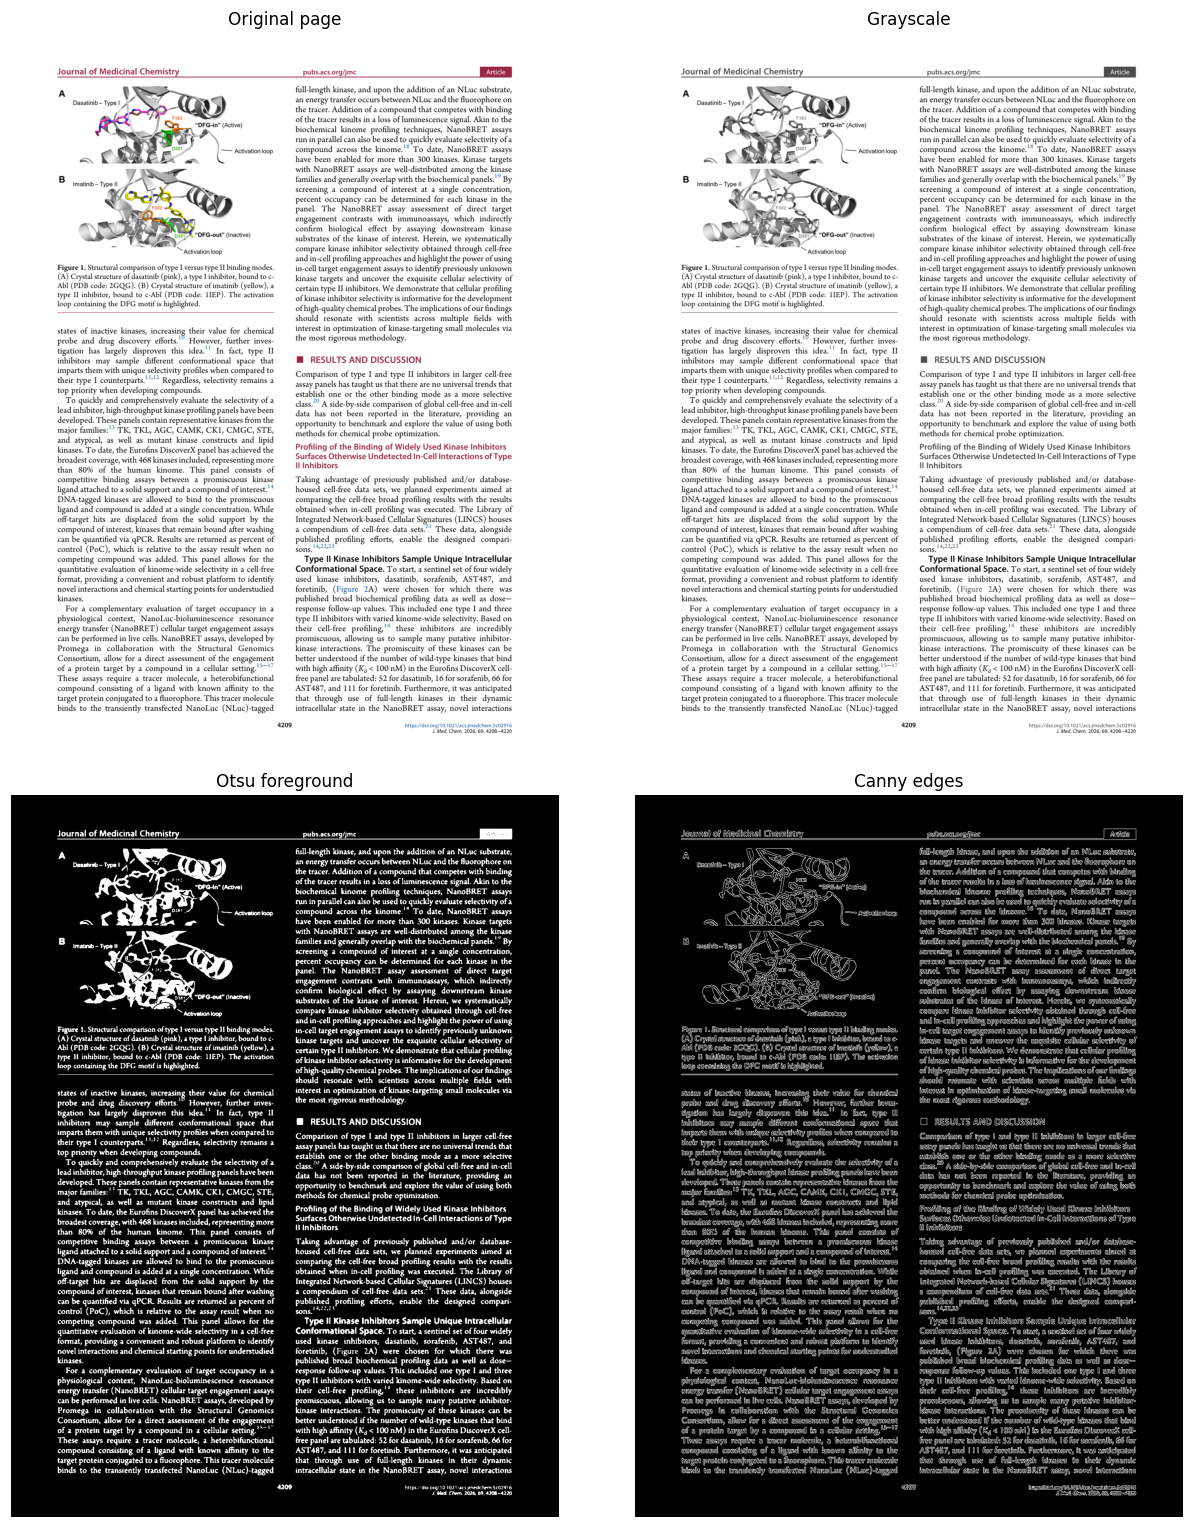

Preprocessing time: 0.015 seconds
Otsu threshold: 190.0


In [68]:
if PAPER_ID not in pdf_by_paper:
    raise ValueError(f"No PDF found for paper {PAPER_ID}.")

pdf_bytes = read_dataset_bytes(DATA_SOURCE, pdf_by_paper[PAPER_ID])
with pymupdf.open(stream=pdf_bytes, filetype="pdf") as document:
    if not 1 <= PAGE_NUMBER <= len(document):
        raise ValueError(f"PAGE_NUMBER must be between 1 and {len(document)}.")
    page = document[PAGE_NUMBER - 1]
    pixmap = page.get_pixmap(dpi=DPI, colorspace=pymupdf.csRGB, alpha=False)
    page_rgb = np.frombuffer(pixmap.samples, dtype=np.uint8).reshape(
        pixmap.height, pixmap.width, 3
    ).copy()
    pdf_page_count = len(document)

prefix = f"paper_{PAPER_ID}_page_{PAGE_NUMBER:03d}"
cv2.imwrite(str(OUTPUT_DIR / f"{prefix}_original.png"),
            cv2.cvtColor(page_rgb, cv2.COLOR_RGB2BGR))
print("Image dimensions:", page_rgb.shape)
print("Pages in the selected PDF:", pdf_page_count)

preprocessing_start = perf_counter()
gray = cv2.cvtColor(page_rgb, cv2.COLOR_RGB2GRAY)
blurred = cv2.GaussianBlur(gray, (3, 3), 0)
otsu_threshold, binary_foreground = cv2.threshold(
    blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)
edges = cv2.Canny(blurred, CANNY_LOW, CANNY_HIGH)
preprocessing_seconds = perf_counter() - preprocessing_start

fig, axes = plt.subplots(2, 2, figsize=(12, 14))
for axis, image, title in zip(
    axes.flat,
    [page_rgb, gray, binary_foreground, edges],
    ["Original page", "Grayscale", "Otsu foreground", "Canny edges"]
):
    axis.imshow(image, cmap="gray" if image.ndim == 2 else None)
    axis.set_title(title)
    axis.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / f"{prefix}_preprocessing.png", dpi=150)
plt.show()
print(f"Preprocessing time: {preprocessing_seconds:.3f} seconds")
print("Otsu threshold:", otsu_threshold)


## 4. Exploratory regions and preprocessing metadata
Morphological closing and contour bounding boxes generate unreviewed page regions. Export their coordinates, crops, overlay, and preprocessing settings. These candidates are not labeled molecule detections; detection precision and recall are not evaluated.

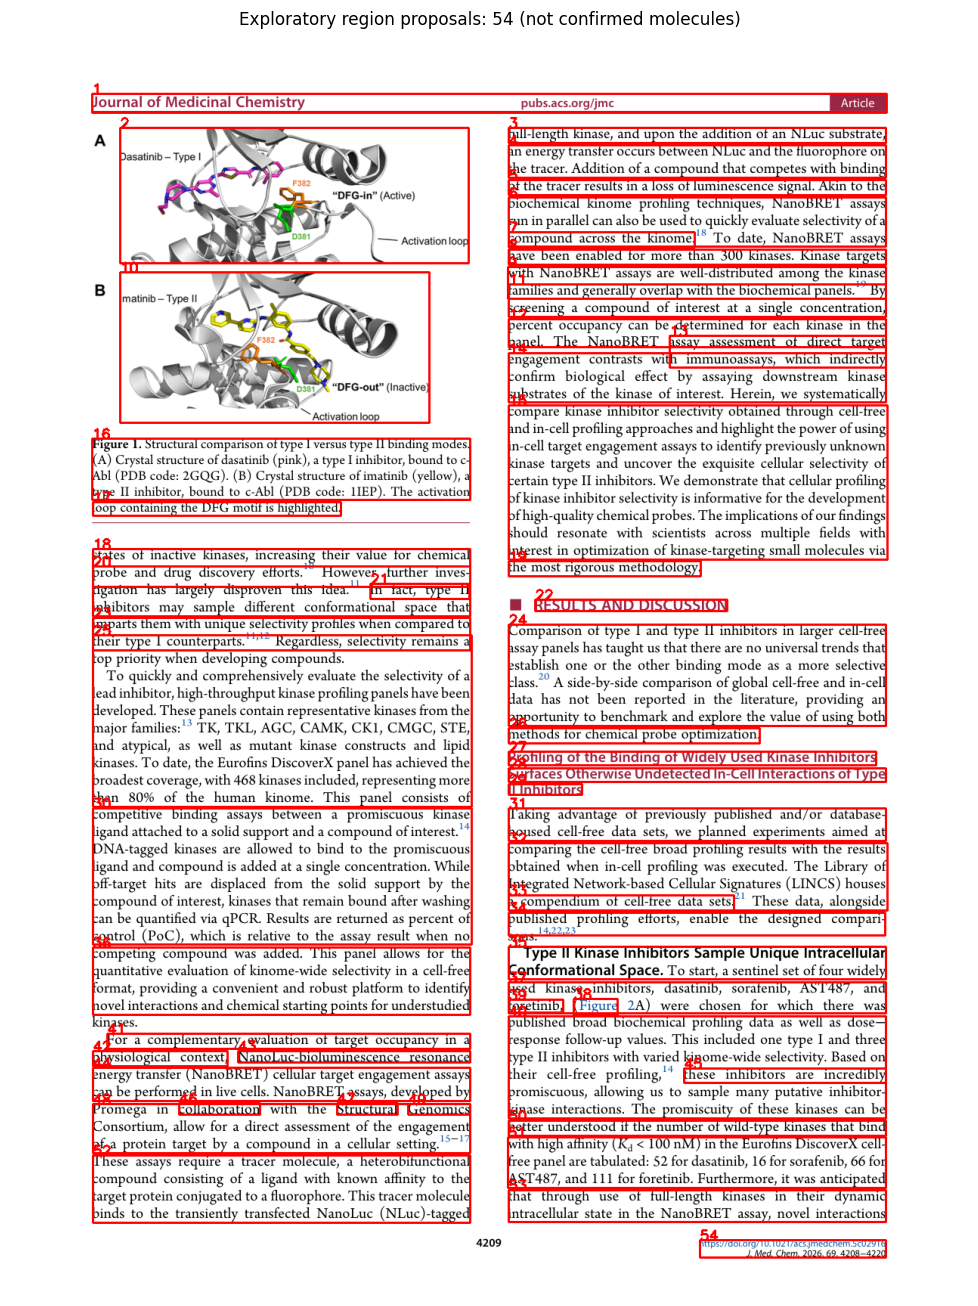

Unreviewed candidate regions: 54
                  region_id paper_id  page_number   x   y  width  height  bbox_area_ratio                                                        crop_path review_status
paper_1_page_002_region_001        1            2 107  80   1051      25         0.012435 paper_1_page_002_candidate_crops/paper_1_page_002_region_001.png    unreviewed
paper_1_page_002_region_002        1            2 144 125    461     179         0.039054 paper_1_page_002_candidate_crops/paper_1_page_002_region_002.png    unreviewed
paper_1_page_002_region_003        1            2 658 125    499      20         0.004723 paper_1_page_002_candidate_crops/paper_1_page_002_region_003.png    unreviewed
paper_1_page_002_region_004        1            2 658 148    499      43         0.010155 paper_1_page_002_candidate_crops/paper_1_page_002_region_004.png    unreviewed
paper_1_page_002_region_005        1            2 658 194    499      20         0.004723 paper_1_page_002_candidate_crops

In [70]:
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, CLOSING_KERNEL)
connected = cv2.morphologyEx(binary_foreground, cv2.MORPH_CLOSE, kernel)
contours, _ = cv2.findContours(connected, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
height, width = gray.shape
page_area = height * width
boxes = []
for contour in contours:
    x, y, box_width, box_height = cv2.boundingRect(contour)
    area_ratio = box_width * box_height / page_area
    if MIN_REGION_AREA_RATIO <= area_ratio <= MAX_REGION_AREA_RATIO:
        boxes.append((x, y, box_width, box_height, area_ratio))
boxes.sort(key=lambda box: (box[1], box[0]))

crop_dir = OUTPUT_DIR / f"{prefix}_candidate_crops"
crop_dir.mkdir(exist_ok=True)
overlay = page_rgb.copy()
region_records = []
for index, (x, y, box_width, box_height, area_ratio) in enumerate(boxes, start=1):
    region_id = f"{prefix}_region_{index:03d}"
    crop_file = crop_dir / f"{region_id}.png"
    crop = page_rgb[y:y + box_height, x:x + box_width]
    cv2.imwrite(str(crop_file), cv2.cvtColor(crop, cv2.COLOR_RGB2BGR))
    cv2.rectangle(overlay, (x, y), (x + box_width, y + box_height), (255, 0, 0), 2)
    cv2.putText(overlay, str(index), (x, max(15, y)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)
    region_records.append({
        "region_id": region_id, "paper_id": PAPER_ID, "page_number": PAGE_NUMBER,
        "x": x, "y": y, "width": box_width, "height": box_height,
        "bbox_area_ratio": area_ratio,
        "crop_path": crop_file.relative_to(OUTPUT_DIR).as_posix(),
        "review_status": "unreviewed"
    })

region_columns = ["region_id", "paper_id", "page_number", "x", "y", "width",
                  "height", "bbox_area_ratio", "crop_path", "review_status"]
regions = pd.DataFrame(region_records, columns=region_columns)
regions.to_csv(OUTPUT_DIR / f"{prefix}_candidate_regions.csv", index=False)
plt.figure(figsize=(9, 12))
plt.imshow(overlay)
plt.title(f"Exploratory region proposals: {len(regions)} (not confirmed molecules)")
plt.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / f"{prefix}_region_overlay.png", dpi=150)
plt.show()
print("Unreviewed candidate regions:", len(regions))
print(regions.head().to_string(index=False))

run_metadata = {
    "stage": "data_audit_and_opencv_pilot",
    "dataset_source": str(DATA_SOURCE),
    "reference_records": len(ground_truth),
    "paper_id": PAPER_ID, "page_number": PAGE_NUMBER, "dpi": DPI,
    "canny_thresholds": [CANNY_LOW, CANNY_HIGH],
    "closing_kernel": list(CLOSING_KERNEL),
    "region_area_ratio_limits": [MIN_REGION_AREA_RATIO, MAX_REGION_AREA_RATIO],
    "preprocessing_seconds": preprocessing_seconds,
    "unreviewed_region_count": len(regions),
    "versions": {"python": sys.version.split()[0], "opencv": cv2.__version__,
                 "numpy": np.__version__, "pandas": pd.__version__,
                 "matplotlib": version("matplotlib"), "pymupdf": version("pymupdf"),
                 "rdkit": rdBase.rdkitVersion},
    "model_inference_performed": False
}
with (OUTPUT_DIR / f"{prefix}_run_metadata.json").open("w", encoding="utf-8") as file:
    json.dump(run_metadata, file, indent=2)
print("Saved data audits, page visualizations, candidate crops, and run metadata.")


## 5. Fixed XN recognition samples
Render four predefined crops from paper 2, PDF page 2, Figure 1C at 300 DPI. Save source document, page, compound label, crop coordinates, and reference SMILES in the manifest. Compound 1h retains its historical pilot label; AKI-062a, D4476, and FP1-24 are exploratory samples.

Crop coordinates are fixed input preparation rather than automatic detection results. Reference SMILES are reserved for evaluation and are not passed to MolGlyph.

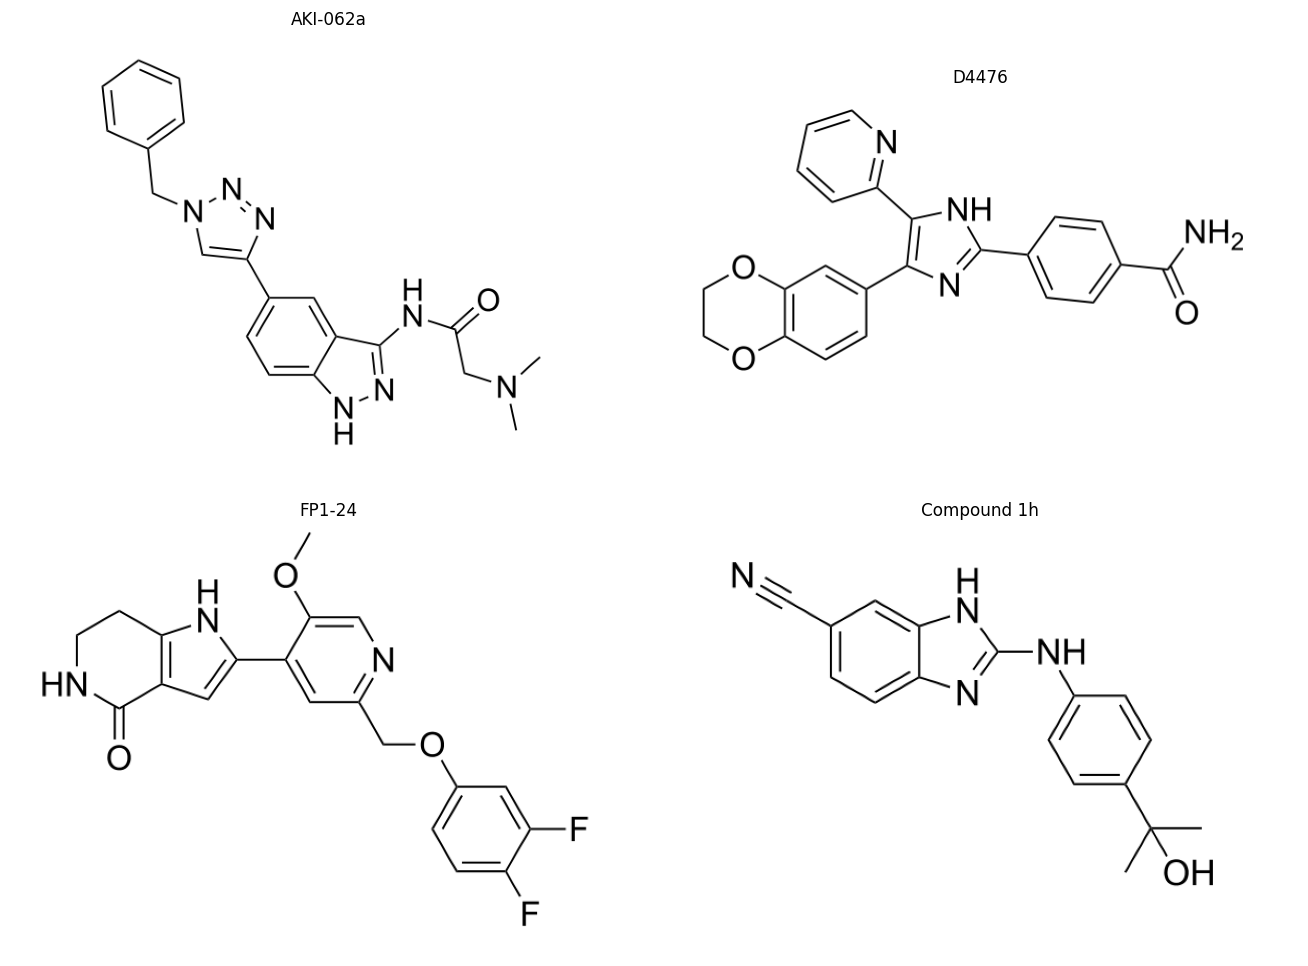

Fixed XN samples: 4
       sample_id sample_usage molecule_name
   XN:2:AKI-062a  exploratory      AKI-062a
      XN:2:D4476  exploratory         D4476
     XN:2:FP1-24  exploratory        FP1-24
XN:2:Compound 1h        pilot   Compound 1h


In [72]:
# Define the sample list before evaluating the new predictions.
XN_SAMPLES = [
    {
        "molecule_name": "AKI-062a",
        "crop": (0.27, 0.275, 0.49, 0.418),
        "sample_usage": "exploratory"
    },
    {
        "molecule_name": "D4476",
        "crop": (0.55, 0.315, 0.80, 0.416),
        "sample_usage": "exploratory"
    },
    {
        "molecule_name": "FP1-24",
        "crop": (0.27, 0.435, 0.51, 0.558),
        "sample_usage": "exploratory"
    },
    {
        "molecule_name": "Compound 1h",
        "crop": (0.56, 0.435, 0.79, 0.553),
        "sample_usage": "pilot"
    }
]

XN_IMAGE_DIR = BENCHMARK_DIR / "xn_images"
XN_IMAGE_DIR.mkdir(parents=True, exist_ok=True)

xn_records = []
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

with pymupdf.open(
    stream=read_dataset_bytes(DATA_SOURCE, pdf_by_paper["2"]),
    filetype="pdf"
) as document:
    page = document[1]

    for index, specification in enumerate(XN_SAMPLES):
        label = specification["molecule_name"]

        matches = ground_truth.loc[
            (ground_truth["paper_id"] == "2") &
            (ground_truth["molecule_name"] == label)
        ]

        if len(matches) != 1:
            raise ValueError(
                f"Expected exactly one reference for paper 2: {label}"
            )

        reference = matches.iloc[0]
        x0, y0, x1, y1 = specification["crop"]

        clip = pymupdf.Rect(
            x0 * page.rect.width,
            y0 * page.rect.height,
            x1 * page.rect.width,
            y1 * page.rect.height
        )

        pixmap = page.get_pixmap(
            dpi=300,
            clip=clip,
            colorspace=pymupdf.csRGB,
            alpha=False
        )

        image_path = XN_IMAGE_DIR / f"paper_2_sample_{index + 1:02d}.png"
        pixmap.save(str(image_path))

        image_rgb = np.frombuffer(
            pixmap.samples, dtype=np.uint8
        ).reshape(pixmap.height, pixmap.width, 3).copy()

        axis = axes.flat[index]
        axis.imshow(image_rgb)
        axis.set_title(label)
        axis.axis("off")

        xn_records.append({
            "dataset": "XN",
            "sample_id": f"XN:2:{label}",
            "sample_usage": specification["sample_usage"],
            "source_document": pdf_by_paper["2"],
            "page_number": 2,
            "molecule_name": label,
            "crop_fractions": json.dumps(specification["crop"]),
            "image_path": image_path.as_posix(),
            "ground_truth_smiles": reference["ground_truth_smiles"]
        })

fig.tight_layout()
plt.show()

xn_manifest = pd.DataFrame(xn_records)
xn_manifest.to_csv(
    BENCHMARK_DIR / "xn_sample_manifest.csv",
    index=False
)

print("Fixed XN samples:", len(xn_manifest))
print(
    xn_manifest[
        ["sample_id", "sample_usage", "molecule_name"]
    ].to_string(index=False)
)


## 6. BioVista OCSR annotation audit
Read `ocsr/labels/gd_SMIELS.csv` and verify every annotation-to-image mapping. Filenames use the source document, the page prefix in `molminer_id`, and the separate global `index` column. Record reference parseability and wildcard exclusions before sample selection.

In [74]:
# Audit the complete public archive before selecting recognition inputs.
if not PUBLIC_ARCHIVE.is_file():
    raise FileNotFoundError(
        f"Archive not found: {PUBLIC_ARCHIVE.resolve()}"
    )

PUBLIC_ROOT.mkdir(parents=True, exist_ok=True)

# Read annotations and list regular archive files.
with tarfile.open(PUBLIC_ARCHIVE, "r:gz") as archive:
    annotation_file = archive.extractfile(
        "ocsr/labels/gd_SMIELS.csv"
    )
    if annotation_file is None:
        raise FileNotFoundError("Annotation CSV not found.")

    with annotation_file:
        annotations = pd.read_csv(
            annotation_file,
            dtype=str,
            keep_default_na=False
        )

    archive_files = {
        member.name
        for member in archive.getmembers()
        if member.isfile()
    }

required_columns = ["pdf_name", "index", "molminer_id", "smiles"]
missing_columns = set(required_columns) - set(annotations.columns)

if missing_columns:
    raise ValueError(f"Missing annotation columns: {missing_columns}")

annotations = annotations[required_columns].copy()

for column in required_columns:
    annotations[column] = annotations[column].str.strip()

# Extract only the page prefix, accepting identifiers such as P3-26null.
page_numbers = annotations["molminer_id"].str.extract(
    r"^P(\d+)-",
    expand=False
)

valid_identifiers = (
    page_numbers.notna() &
    annotations["index"].str.fullmatch(r"[0-9]+", na=False)
)

if not valid_identifiers.all():
    invalid_rows = annotations.loc[
        ~valid_identifiers,
        ["pdf_name", "index", "molminer_id"]
    ]
    raise ValueError(
        "Unusable identifiers:\n" + invalid_rows.to_string(index=False)
    )

annotations["page_number"] = page_numbers.astype(int)
image_indices = annotations["index"].astype(int).astype(str)

# Filenames use the page number and the separate global index column.
annotations["archive_image_path"] = (
    "ocsr/data/" +
    annotations["pdf_name"] +
    "_image_molminer_bbox_" +
    annotations["page_number"].astype(str) +
    "-" + image_indices + ".png"
)

annotations["sample_id"] = (
    "BioVista_OCSR:" +
    annotations["pdf_name"] +
    ":" + image_indices
)

if annotations["sample_id"].duplicated().any():
    raise ValueError("Duplicate sample IDs.")

if annotations["archive_image_path"].duplicated().any():
    raise ValueError("Multiple annotations map to the same image.")

# Verify image-to-reference matching before selecting samples.
missing_images = [
    name
    for name in annotations["archive_image_path"]
    if name not in archive_files
]

if missing_images:
    raise FileNotFoundError(
        f"Missing archive images: {missing_images[:5]}"
    )

# Audit reference validity without using model predictions.
def reference_is_valid(smiles):
    if not smiles:
        return False
    try:
        with rdBase.BlockLogs():
            return Chem.MolFromSmiles(smiles) is not None
    except Exception:
        return False

annotations["contains_wildcard"] = annotations["smiles"].str.contains(
    "*", regex=False
)
annotations["reference_valid"] = annotations["smiles"].map(
    reference_is_valid
)
annotations["eligible"] = (
    ~annotations["contains_wildcard"] &
    annotations["reference_valid"]
)

annotations["exclusion_reason"] = np.select(
    [
        annotations["contains_wildcard"],
        ~annotations["reference_valid"]
    ],
    ["wildcard_reference", "invalid_reference"],
    default=""
)

annotations.to_csv(
    PUBLIC_ROOT / "reference_audit.csv",
    index=False
)

print("Total annotations:", len(annotations))
print("Matched images:", len(annotations))
print("Wildcard references:", int(annotations["contains_wildcard"].sum()))
print("Invalid references:", int((~annotations["reference_valid"]).sum()))
print("Eligible references:", int(annotations["eligible"].sum()))


Total annotations: 8861
Matched images: 8861
Wildcard references: 4017
Invalid references: 1
Eligible references: 4843


## 7. Public subset preparation and frozen manifest
Sort the eligible pool by sample ID and select 100 records using seed 42. Extract only selected images and verify their readability without altering image contents. Save exclusion counts and sampling metadata.

Combine public and XN records into a fixed manifest before inference. Saved manifests must match the current sample IDs, references, provenance, and project-relative image paths. The public results describe this eligible subset rather than the entire BioVista dataset.

In [105]:
# Fix the eligible pool and sampling rule before inference.
eligible = (
    annotations.loc[annotations["eligible"]]
    .sort_values("sample_id")
    .reset_index(drop=True)
)

if len(eligible) < PUBLIC_SAMPLE_SIZE:
    raise ValueError(
        f"Requested {PUBLIC_SAMPLE_SIZE} samples, "
        f"but only {len(eligible)} are eligible."
    )

selected = (
    eligible.sample(
        n=PUBLIC_SAMPLE_SIZE,
        random_state=PUBLIC_RANDOM_SEED
    )
    .sort_values("sample_id")
    .reset_index(drop=True)
)

PUBLIC_IMAGE_DIR = PUBLIC_ROOT / "data"
PUBLIC_IMAGE_DIR.mkdir(parents=True, exist_ok=True)

public_records = []

# Read only the selected image files; no full extraction is required.
with tarfile.open(PUBLIC_ARCHIVE, "r:gz") as archive:
    for _, row in selected.iterrows():
        member_name = row["archive_image_path"]
        member = archive.getmember(member_name)

        if not member.isfile():
            raise ValueError(f"Not a regular image file: {member_name}")

        source = archive.extractfile(member)
        if source is None:
            raise OSError(f"Cannot read archive image: {member_name}")

        with source:
            image_bytes = source.read()

        # Verify decoding without changing the original image.
        decoded = cv2.imdecode(
            np.frombuffer(image_bytes, dtype=np.uint8),
            cv2.IMREAD_COLOR
        )
        if decoded is None:
            raise ValueError(f"Unreadable image: {member_name}")

        image_path = PUBLIC_IMAGE_DIR / Path(member_name).name
        image_path.write_bytes(image_bytes)

        public_records.append({
            "dataset": "BioVista_OCSR",
            "sample_id": row["sample_id"],
            "sample_usage": "fixed_public_nonwildcard_subset",
            "source_document": row["pdf_name"],
            "page_number": int(row["page_number"]),
            "molecule_name": row["molminer_id"],
            "crop_fractions": "",
            "image_path": image_path.as_posix(),
            "ground_truth_smiles": row["smiles"]
        })

# Use the same manifest columns as the XN samples.
public_manifest = pd.DataFrame(public_records)

public_manifest.to_csv(
    BENCHMARK_DIR / "public_sample_manifest.csv",
    index=False
)

# Record the selection scope and exclusions for the report.
selection_metadata = {
    "archive": PUBLIC_ARCHIVE.name,
    "annotation_file": "ocsr/labels/gd_SMIELS.csv",
    "total_reference_records": len(annotations),
    "wildcard_reference_records": int(
        annotations["contains_wildcard"].sum()
    ),
    "invalid_reference_records": int(
        (~annotations["reference_valid"]).sum()
    ),
    "eligible_reference_records": len(eligible),
    "selected_samples": len(public_manifest),
    "random_seed": PUBLIC_RANDOM_SEED,
    "scope": "RDKit-parseable references without wildcard atoms",
    "image_mapping": "pdf_name + page_number + global index"
}

with (PUBLIC_ROOT / "selection_metadata.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(selection_metadata, file, indent=2)

print("Prepared public samples:", len(public_manifest))
print("Random seed:", PUBLIC_RANDOM_SEED)
print("Image directory:", PUBLIC_IMAGE_DIR.resolve())
print(public_manifest.head().to_string(index=False))

evaluation_manifest = pd.concat(
    [xn_manifest, public_manifest],
    ignore_index=True
).sort_values("sample_id").reset_index(drop=True)

if evaluation_manifest["sample_id"].duplicated().any():
    raise ValueError("Duplicate evaluation sample IDs.")

manifest_file = BENCHMARK_DIR / "fixed_combined_manifest.csv"

comparison_columns = [
    "sample_id", "image_path", "ground_truth_smiles",
    "sample_usage", "source_document", "page_number", "crop_fractions"
]

if manifest_file.exists():
    saved = pd.read_csv(
        manifest_file,
        dtype=str,
        keep_default_na=False
    )

    saved_values = (
        saved[comparison_columns]
        .fillna("")
        .astype(str)
        .reset_index(drop=True)
    )
    current_values = (
        evaluation_manifest[comparison_columns]
        .fillna("")
        .astype(str)
        .reset_index(drop=True)
    )

    if not saved_values.equals(current_values):
        raise ValueError(
            "The sample list differs from the saved experiment. "
            "Use a new BENCHMARK_DIR for a changed experiment."
        )
else:
    evaluation_manifest.to_csv(manifest_file, index=False)

print(
    evaluation_manifest.groupby(
        ["dataset", "sample_usage"]
    ).size().to_string()
)
print("Fixed manifest:", manifest_file.resolve())


Prepared public samples: 100
Random seed: 42
Image directory: C:\Users\yxu\Desktop\AAI6630 Benchmarking Code\BioVista_OCSR\data
      dataset                 sample_id                    sample_usage source_document  page_number molecule_name crop_fractions                                               image_path                                        ground_truth_smiles
BioVista_OCSR  BioVista_OCSR:100_6qm7:8 fixed_public_nonwildcard_subset        100_6qm7            2          P2-9                 BioVista_OCSR/data/100_6qm7_image_molminer_bbox_2-8.png        O=C(Nc1ccc(F)c(-c2cn3nc(-c4ccccc4)cnc3n2)c1)N1CCCC1
BioVista_OCSR  BioVista_OCSR:102_6ql3:2 fixed_public_nonwildcard_subset        102_6ql3            6          P6-3                 BioVista_OCSR/data/102_6ql3_image_molminer_bbox_6-2.png                     NS(=O)(=O)c1c(F)c(F)c(N2CCOCC2)c(F)c1F
BioVista_OCSR BioVista_OCSR:102_6ql3:29 fixed_public_nonwildcard_subset        102_6ql3            6         P6-30                BioV

## 8. Model and official caption decoder
Load the standalone MolGlyph component and its checkpoint once on CPU. Load BioMiner's official abbreviation decoder directly, using the accompanying abbreviation table. This avoids initializing the full BioMiner pipeline.

The decoder processes model captions containing `<sep>` and abbreviation annotations. Reconstructed outputs with remaining dummy atoms are classified as unresolved structures. Decoding uses only model output and the official abbreviation table.

In [107]:
# Import the OCSR package without initializing the full BioMiner system.
import torch

OCSR_PACKAGE_ROOT = BIOMINER_ROOT / "BioMiner" / "MolScribe"

if not (OCSR_PACKAGE_ROOT / "molscribe").is_dir():
    raise FileNotFoundError(
        f"OCSR package not found: {OCSR_PACKAGE_ROOT}"
    )

if not MODEL_PATH.is_file():
    raise FileNotFoundError(f"Checkpoint not found: {MODEL_PATH}")

# Add the parent directory of the standalone molscribe package.
package_path = str(OCSR_PACKAGE_ROOT.resolve())
if package_path not in sys.path:
    sys.path.insert(0, package_path)

from molscribe import MolGlyph

device = torch.device("cpu")
load_start = perf_counter()

ocsr_model = MolGlyph(
    str(MODEL_PATH),
    device=device,
    num_workers=1
)

print("Device:", device)
print(f"Model loading time: {perf_counter() - load_start:.2f} seconds")

# Load the official abbreviation decoder without initializing BioMiner.
utility_path = (
    BIOMINER_ROOT / "BioMiner" / "commons" / "molglyph_utils.py"
)

if not utility_path.is_file():
    raise FileNotFoundError(f"Utility not found: {utility_path}")

if not (utility_path.parent / "abbrevs.csv").is_file():
    raise FileNotFoundError("The official abbrevs.csv file is missing.")

module_name = "molglyph_postprocessing"
spec = importlib.util.spec_from_file_location(module_name, utility_path)

molglyph_utils = importlib.util.module_from_spec(spec)
sys.modules[module_name] = molglyph_utils
spec.loader.exec_module(molglyph_utils)


def decode_molglyph_output(raw):
    """Expand predicted abbreviations using the official decoder."""
    caption = raw.strip()

    if not caption:
        return "", "empty_output", ""

    try:
        if "<sep>" in caption:
            translated = molglyph_utils.Translator.refactor(caption)

            if translated is None:
                return "", "postprocessing_error", (
                    "The official decoder could not reconstruct the caption."
                )

            smiles = translated.smi
        else:
            smiles = caption

        with rdBase.BlockLogs():
            molecule = Chem.MolFromSmiles(smiles)

        if molecule is None:
            return smiles, "invalid_smiles", ""

        # A remaining dummy atom is an unresolved structure component.
        if any(atom.GetAtomicNum() == 0 for atom in molecule.GetAtoms()):
            return smiles, "unresolved_group", ""

        return smiles, "ok", ""

    except Exception as error:
        return "", "postprocessing_error", (
            f"{type(error).__name__}: {error}"
        )


Device: cpu
Model loading time: 2.05 seconds


## 9. Batch inference and caption reconstruction
Process each image once, preserving raw model captions, model-call status, elapsed time, and errors. Save progress after every image, then apply the official decoder uniformly to successful model calls. Retain empty outputs, inference errors, reconstruction failures, and unresolved groups.

`inference_seconds` measures the readability check and model call, including image loading. It excludes model initialization and the subsequent decoding and metric stages. Confidence values are unavailable in the interface used here.

In [109]:
# Create a separate result directory and preserve the raw inference stage.
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
RUN_DIR = BENCHMARK_DIR / f"run_{run_id}"
RUN_DIR.mkdir(parents=True, exist_ok=False)

evaluation_manifest.to_csv(
    RUN_DIR / "sample_manifest.csv",
    index=False
)

prediction_records = []

for position, (_, sample) in enumerate(
    evaluation_manifest.iterrows(),
    start=1
):
    record = sample.to_dict()
    record.update({
        "tool": "BioMiner MolGlyph",
        "raw_predicted_smiles": "",
        "predicted_smiles": "",
        "inference_status": "ok",
        "inference_error": ""
    })

    image_path = Path(sample["image_path"])
    start = perf_counter()

    try:
        if cv2.imread(str(image_path)) is None:
            raise ValueError(f"Image missing or unreadable: {image_path}")

        prediction = ocsr_model.predict_image_file(
            str(image_path),
            return_atoms_bonds=False,
            return_confidence=False
        )

        if not isinstance(prediction, str):
            raise TypeError(
                f"Expected str, received {type(prediction).__name__}"
            )

        record["raw_predicted_smiles"] = prediction
        record["predicted_smiles"] = prediction.strip()

        if not record["predicted_smiles"]:
            record["inference_status"] = "empty_output"

    except Exception as error:
        record["inference_status"] = "inference_error"
        record["inference_error"] = (
            f"{type(error).__name__}: {error}"
        )

    record["inference_seconds"] = perf_counter() - start
    prediction_records.append(record)

    pd.DataFrame(prediction_records).to_csv(
        RUN_DIR / "predictions.csv",
        index=False
    )

    print(
        f"[{position}/{len(evaluation_manifest)}] "
        f"{sample['sample_id']} — {record['inference_status']} — "
        f"{record['inference_seconds']:.2f}s"
    )

predictions = pd.DataFrame(prediction_records)

run_metadata = {
    "run_id": run_id,
    "tool": "BioMiner MolGlyph",
    "device": str(device),
    "sample_count": len(evaluation_manifest),
    "public_benchmark_included": True,
    "public_sample_seed": PUBLIC_RANDOM_SEED,
    "versions": environment_versions,
    "checkpoint": str(MODEL_PATH),
    "checkpoint_bytes": MODEL_PATH.stat().st_size,
    "normalization": "official Translator.refactor for caption abbreviations; unresolved groups retained as failures",
    "confidence_available": False,
    "timing": "image readability check and model call; excludes model loading, official decoding, and metrics",
    "fingerprint": {"type": "Morgan", "radius": 2, "bits": 2048, "include_chirality": True},
    "exact_match_rule": "canonical isomeric SMILES; all fragments retained"
}

with (RUN_DIR / "run_metadata.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(run_metadata, file, indent=2)

print("Saved predictions:", RUN_DIR.resolve())

# Preserve original predictions and inference status.
if "model_inference_status" not in predictions.columns:
    predictions["model_inference_status"] = predictions["inference_status"]

predictions["postprocessing_status"] = ""
predictions["postprocessing_error"] = ""

for index, row in predictions.iterrows():
    if row["model_inference_status"] != "ok":
        continue

    smiles, status, error = decode_molglyph_output(
        row["raw_predicted_smiles"]
    )

    predictions.at[index, "predicted_smiles"] = smiles
    predictions.at[index, "postprocessing_status"] = status
    predictions.at[index, "postprocessing_error"] = error

    # Prevent unresolved or invalid outputs from being scored as complete molecules.
    predictions.at[index, "inference_status"] = status

predictions.to_csv(
    RUN_DIR / "predictions_postprocessed.csv",
    index=False
)

print(predictions["postprocessing_status"].value_counts().to_string())


[1/104] BioVista_OCSR:100_6qm7:8 — ok — 1.36s
[2/104] BioVista_OCSR:102_6ql3:2 — ok — 1.03s
[3/104] BioVista_OCSR:102_6ql3:29 — ok — 1.37s
[4/104] BioVista_OCSR:108_6qhc:4 — ok — 0.84s
[5/104] BioVista_OCSR:113_6qeg:18 — ok — 0.88s
[6/104] BioVista_OCSR:117_6qav:6 — ok — 1.49s
[7/104] BioVista_OCSR:119_6qae:43 — ok — 1.26s
[8/104] BioVista_OCSR:123_6q8c:14 — ok — 1.79s
[9/104] BioVista_OCSR:130_6q4g:10 — ok — 0.63s
[10/104] BioVista_OCSR:130_6q4g:70 — ok — 1.36s
[11/104] BioVista_OCSR:132_6q39:29 — ok — 1.08s
[12/104] BioVista_OCSR:136_6pyu:32 — ok — 1.23s
[13/104] BioVista_OCSR:136_6pyu:39 — ok — 1.28s
[14/104] BioVista_OCSR:141_6pvz:24 — ok — 0.75s
[15/104] BioVista_OCSR:141_6pvz:33 — ok — 0.76s
[16/104] BioVista_OCSR:143_6pvs:20 — ok — 0.41s
[17/104] BioVista_OCSR:143_6pvs:3 — ok — 0.72s
[18/104] BioVista_OCSR:143_6pvs:50 — ok — 1.83s
[19/104] BioVista_OCSR:146_6psb:13 — ok — 0.56s
[20/104] BioVista_OCSR:151_6pno:2 — ok — 0.90s
[21/104] BioVista_OCSR:151_6pno:36 — ok — 0.97s
[22/104

## 10. Chemical evaluation and per-sample results
Exact match compares RDKit canonical isomeric SMILES, preserving stereochemistry and disconnected fragments. Similarity uses Morgan fingerprints with radius 2, 2048 bits, and chirality enabled. Fingerprint Tanimoto equal to 1 does not establish exact structural identity.

All selected samples remain in the accuracy denominator. Failed, empty, invalid, and unresolved predictions count as incorrect. Their raw Tanimoto is missing; a separately reported failure-penalized Tanimoto assigns zero. Export raw captions, reconstructed SMILES, chemical scores, provenance, and failure categories.

In [111]:
fingerprint_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048,
    includeChirality=True
)

evaluated_records = []

for _, prediction in predictions.iterrows():
    record = prediction.to_dict()

    reference_molecule = Chem.MolFromSmiles(
        record["ground_truth_smiles"]
    )
    if reference_molecule is None:
        raise ValueError(
            f"Invalid reference for {record['sample_id']}"
        )

    reference_canonical = Chem.MolToSmiles(
        reference_molecule,
        canonical=True,
        isomericSmiles=True
    )

    predicted_molecule = None
    if record["inference_status"] == "ok":
        predicted_molecule = Chem.MolFromSmiles(
            record["predicted_smiles"]
        )

    valid_prediction = predicted_molecule is not None
    predicted_canonical = None
    exact_match = False
    tanimoto = np.nan

    if valid_prediction:
        predicted_canonical = Chem.MolToSmiles(
            predicted_molecule,
            canonical=True,
            isomericSmiles=True
        )

        exact_match = predicted_canonical == reference_canonical

        tanimoto = float(DataStructs.TanimotoSimilarity(
            fingerprint_generator.GetFingerprint(reference_molecule),
            fingerprint_generator.GetFingerprint(predicted_molecule)
        ))

        evaluation_status = (
            "exact_match" if exact_match else "valid_but_incorrect"
        )
    else:
        evaluation_status = (
            "invalid_smiles"
            if record["inference_status"] == "ok"
            else record["inference_status"]
        )

    record.update({
        "reference_canonical_smiles": reference_canonical,
        "prediction_canonical_smiles": predicted_canonical,
        "valid_prediction": valid_prediction,
        "exact_match": exact_match,
        "tanimoto": tanimoto,
        "tanimoto_failure_penalized": (
            tanimoto if valid_prediction else 0.0
        ),
        "evaluation_status": evaluation_status
    })

    evaluated_records.append(record)

evaluated = pd.DataFrame(evaluated_records)
evaluated.to_csv(
    RUN_DIR / "evaluated_predictions.csv",
    index=False
)

print(
    evaluated[
        ["dataset", "sample_id", "evaluation_status",
         "exact_match", "tanimoto"]
    ].to_string(index=False)
)


      dataset                  sample_id    evaluation_status  exact_match  tanimoto
BioVista_OCSR   BioVista_OCSR:100_6qm7:8          exact_match         True  1.000000
BioVista_OCSR   BioVista_OCSR:102_6ql3:2          exact_match         True  1.000000
BioVista_OCSR  BioVista_OCSR:102_6ql3:29          exact_match         True  1.000000
BioVista_OCSR   BioVista_OCSR:108_6qhc:4          exact_match         True  1.000000
BioVista_OCSR  BioVista_OCSR:113_6qeg:18  valid_but_incorrect        False  0.780488
BioVista_OCSR   BioVista_OCSR:117_6qav:6          exact_match         True  1.000000
BioVista_OCSR  BioVista_OCSR:119_6qae:43          exact_match         True  1.000000
BioVista_OCSR  BioVista_OCSR:123_6q8c:14     unresolved_group        False       NaN
BioVista_OCSR  BioVista_OCSR:130_6q4g:10          exact_match         True  1.000000
BioVista_OCSR  BioVista_OCSR:130_6q4g:70     unresolved_group        False       NaN
BioVista_OCSR  BioVista_OCSR:132_6q39:29  valid_but_incorrect    

## Visual inspection of recognition errors

Compare each unsuccessful prediction with its source image and reference
structure. Display the reconstructed prediction when it is a complete,
valid molecule; otherwise retain the raw caption and failure category.

Reference structures are used only for evaluation and visual inspection.
This analysis does not modify predictions or benchmark scores.

Cases without an exact match: 28


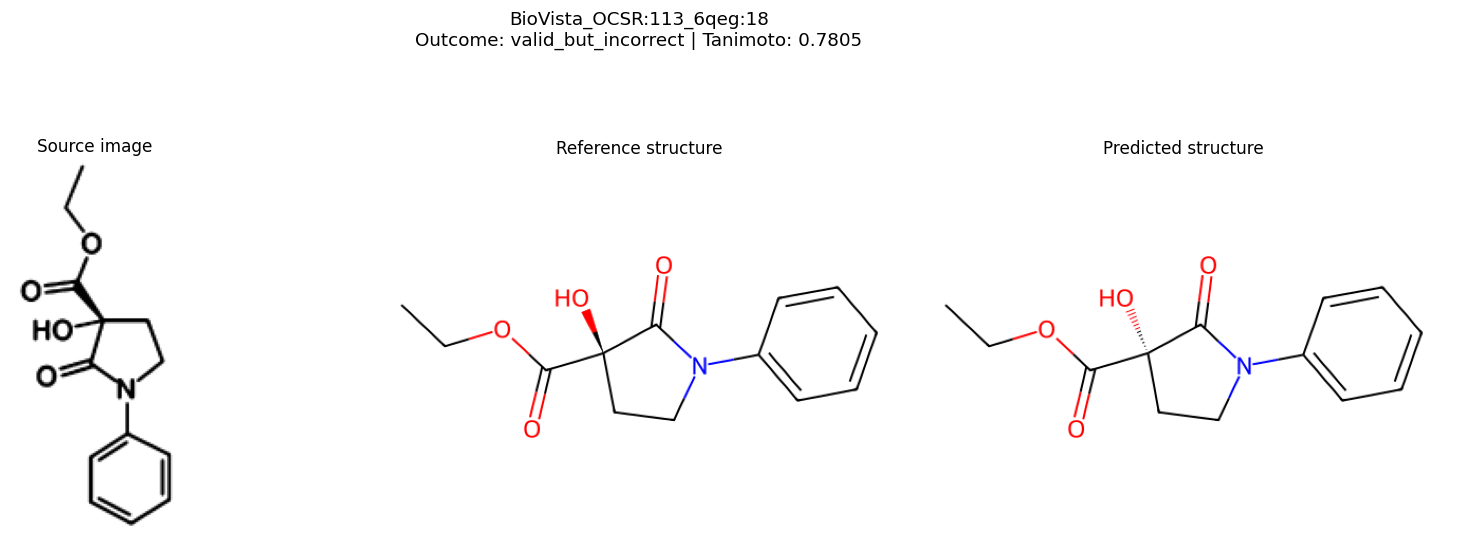

Sample ID: BioVista_OCSR:113_6qeg:18
Reference SMILES: CCOC(=O)[C@@]1(O)CCN(c2ccccc2)C1=O
Reconstructed prediction: CCOC(=O)[C@]1(O)CCN(c2ccccc2)C1=O
Raw model caption:
CCOC(=O)[C@]1(O)CCN(c2ccccc2)C1=O<sep>
Saved comparison: outputs\benchmark_n100_seed42\run_20261014T055719_105367Z\error_comparisons\error_case_001.png
--------------------------------------------------------------------------------


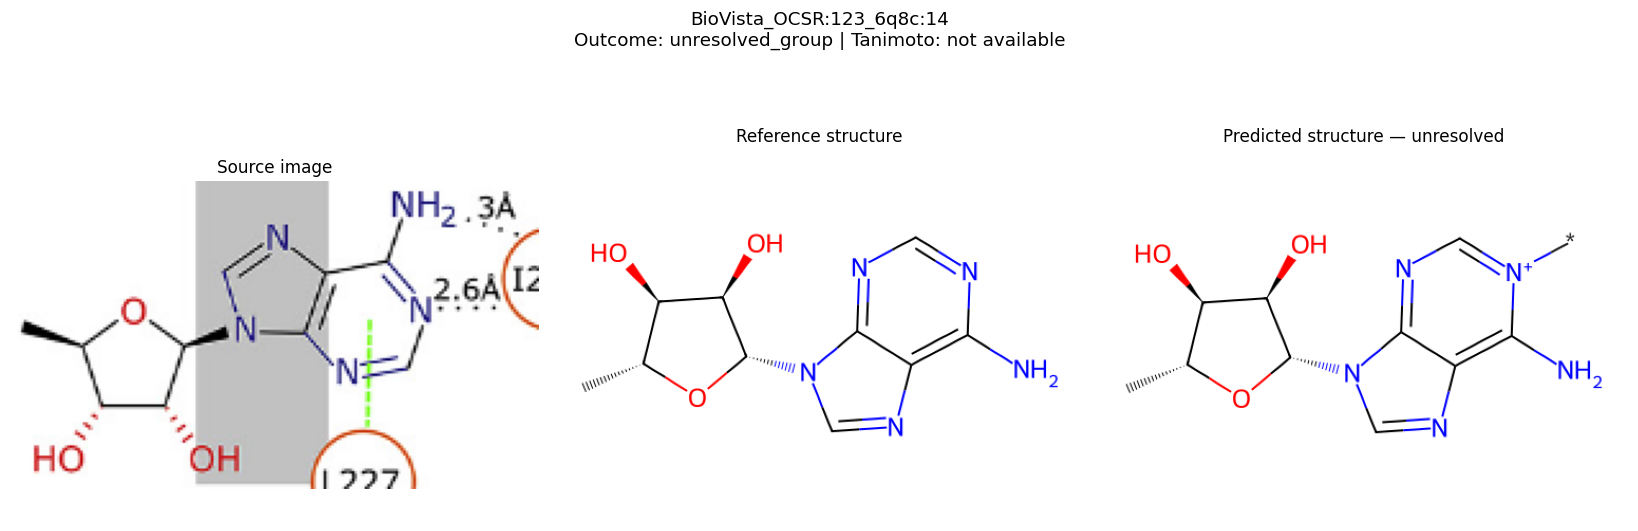

Sample ID: BioVista_OCSR:123_6q8c:14
Reference SMILES: C[C@H]1O[C@@H](n2cnc3c(N)ncnc32)[C@H](O)[C@@H]1O
Reconstructed prediction: C[C@H]1O[C@@H](n2cnc3c(N)[n+](*)cnc32)[C@H](O)[C@@H]1O
Raw model caption:
C[C@@H]1[C@@H](O)[C@@H](O)[C@H](N2C3C(=C([N+](=CN=3)*)N)N=C2)O1<sep><a>14:<dum></a>
Saved comparison: outputs\benchmark_n100_seed42\run_20261014T055719_105367Z\error_comparisons\error_case_002.png
--------------------------------------------------------------------------------


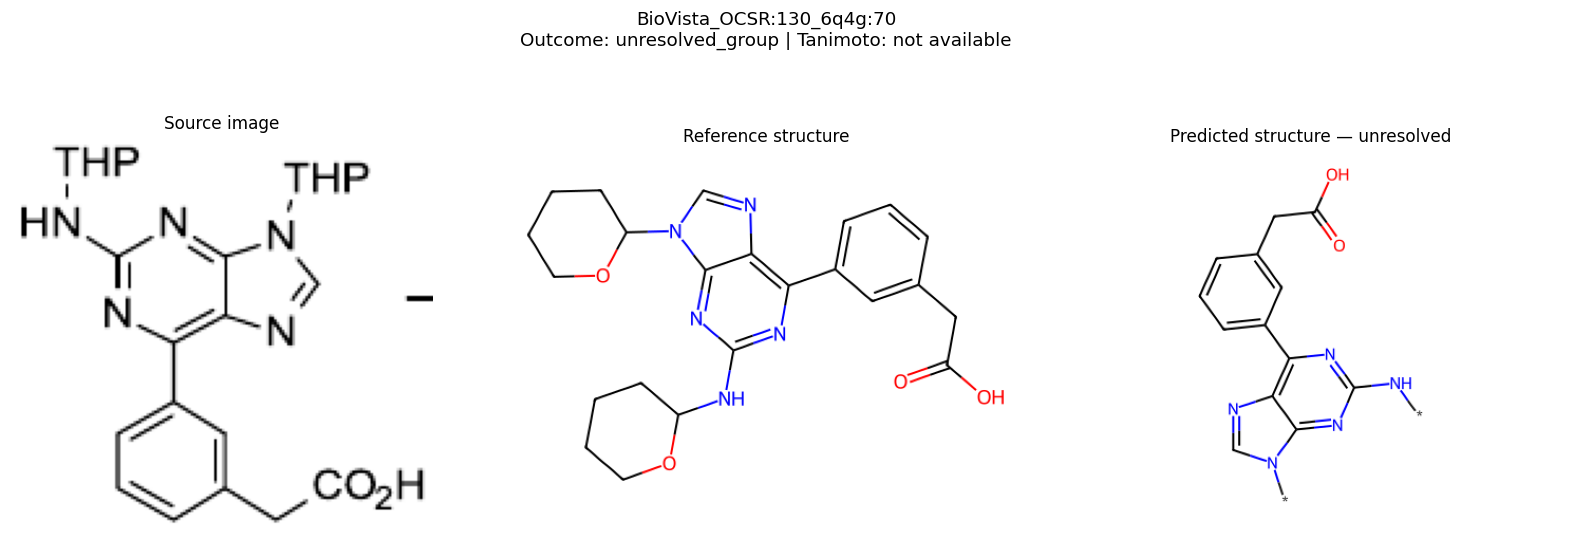

Sample ID: BioVista_OCSR:130_6q4g:70
Reference SMILES: O=C(O)Cc1cccc(-c2nc(NC3CCCCO3)nc3c2ncn3C2CCCCO2)c1
Reconstructed prediction: C(=O)(O)Cc1cccc(-c2nc(N*)nc3c2ncn3*)c1
Raw model caption:
C(CC1=CC=CC(C2N=C(N*)N=C3C=2N=CN3*)=C1)(=O)O<sep><a>11:THP</a><a>18:THP</a>
Saved comparison: outputs\benchmark_n100_seed42\run_20261014T055719_105367Z\error_comparisons\error_case_003.png
--------------------------------------------------------------------------------


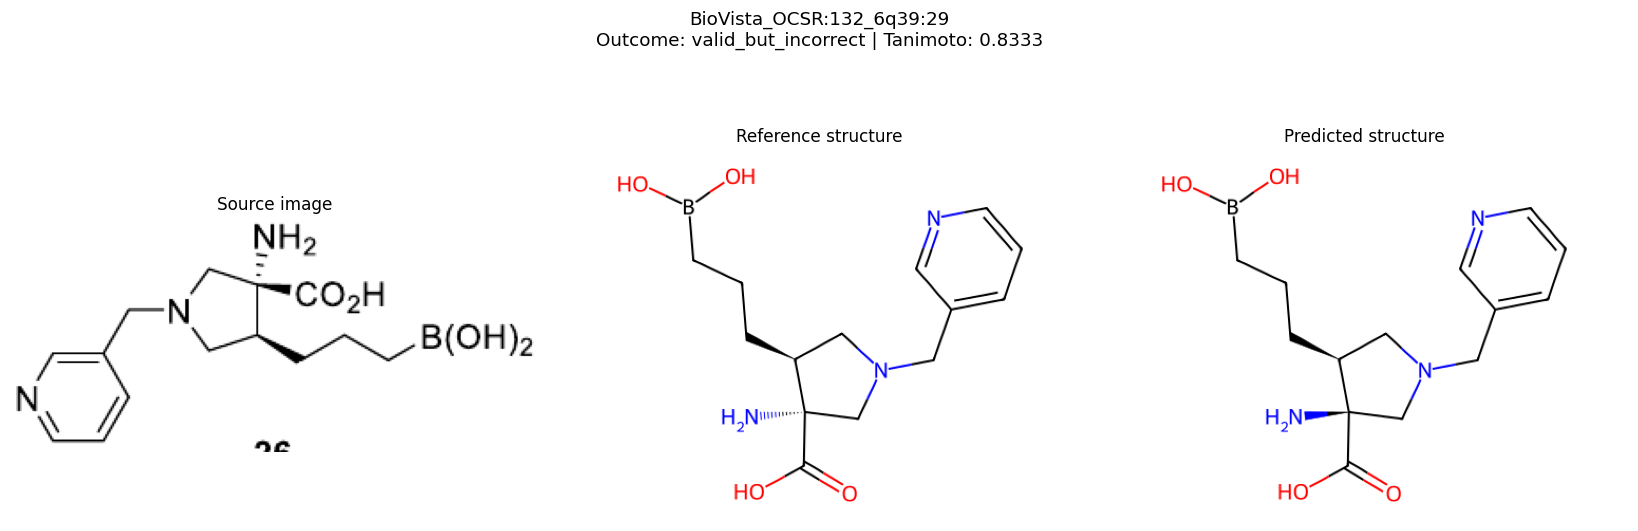

Sample ID: BioVista_OCSR:132_6q39:29
Reference SMILES: N[C@@]1(C(=O)O)CN(Cc2cccnc2)C[C@@H]1CCCB(O)O
Reconstructed prediction: B(O)(O)CCC[C@H]1CN(Cc2cccnc2)C[C@]1(N)C(=O)O
Raw model caption:
B(CCC[C@H]1CN(Cc2cccnc2)C[C@]1(N)C(=O)O)(O)O<sep>
Saved comparison: outputs\benchmark_n100_seed42\run_20261014T055719_105367Z\error_comparisons\error_case_004.png
--------------------------------------------------------------------------------


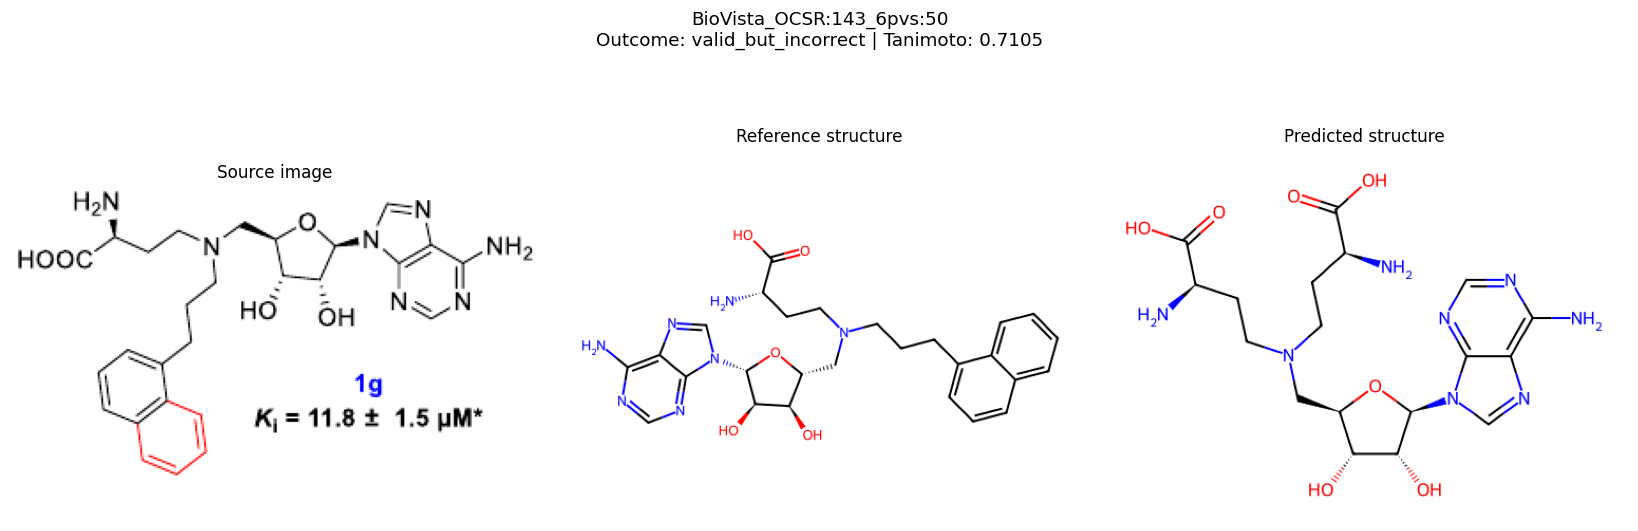

Sample ID: BioVista_OCSR:143_6pvs:50
Reference SMILES: Nc1ncnc2c1ncn2[C@@H]1O[C@H](CN(CCCc2cccc3ccccc23)CC[C@H](N)C(=O)O)[C@@H](O)[C@H]1O
Reconstructed prediction: Nc1ncnc2c1ncn2[C@@H]1O[C@H](CN(CC[C@@H](N)C(=O)O)CC[C@H](N)C(=O)O)[C@@H](O)[C@H]1O
Raw model caption:
Nc1ncnc2c1ncn2[C@@H]1O[C@H](CN(CC[C@@H](N)C(=O)O)CC[C@H](N)C(=O)O)[C@@H](O)[C@H]1O<se
p>
Saved comparison: outputs\benchmark_n100_seed42\run_20261014T055719_105367Z\error_comparisons\error_case_005.png
--------------------------------------------------------------------------------


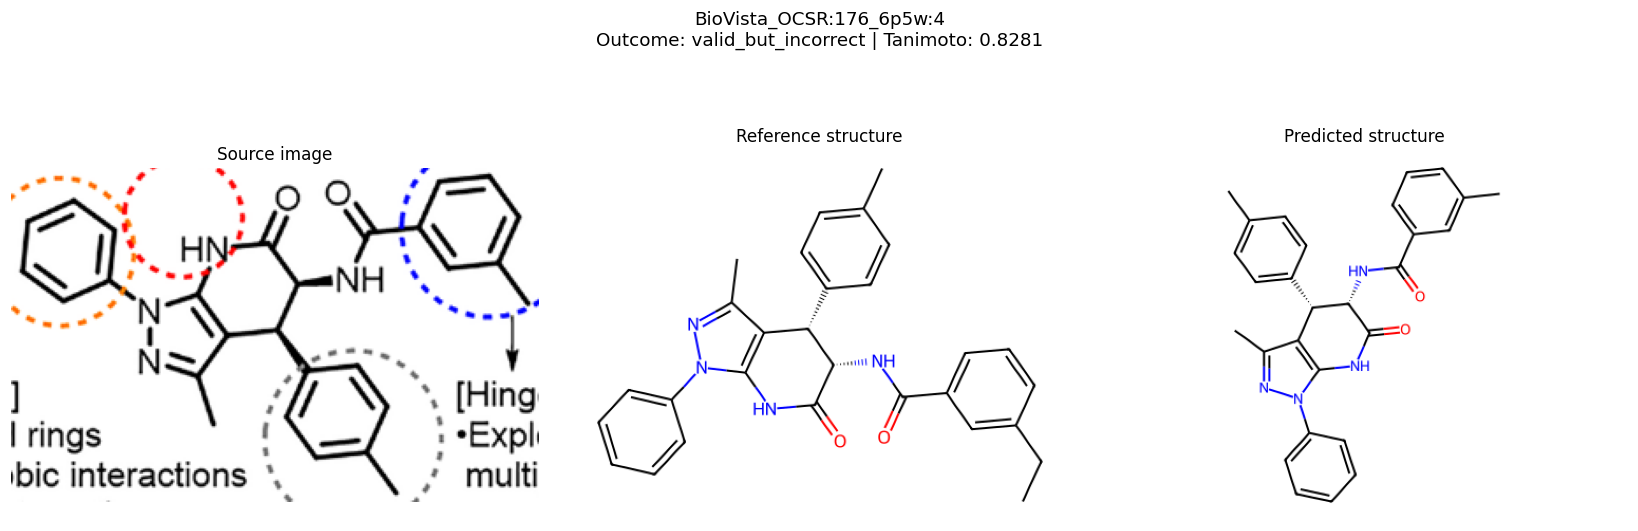

Sample ID: BioVista_OCSR:176_6p5w:4
Reference SMILES: CCc1cccc(C(=O)N[C@@H]2C(=O)Nc3c(c(C)nn3-c3ccccc3)[C@@H]2c2ccc(C)cc2)c1
Reconstructed prediction: Cc1cccc(C(=O)N[C@@H]2C(=O)Nc3c(c(C)nn3-c3ccccc3)[C@@H]2c2ccc(C)cc2)c1
Raw model caption:
Cc1cccc(C(=O)N[C@@H]2C(=O)Nc3c(c(C)nn3-c3ccccc3)[C@@H]2c2ccc(C)cc2)c1<sep>
Saved comparison: outputs\benchmark_n100_seed42\run_20261014T055719_105367Z\error_comparisons\error_case_006.png
--------------------------------------------------------------------------------


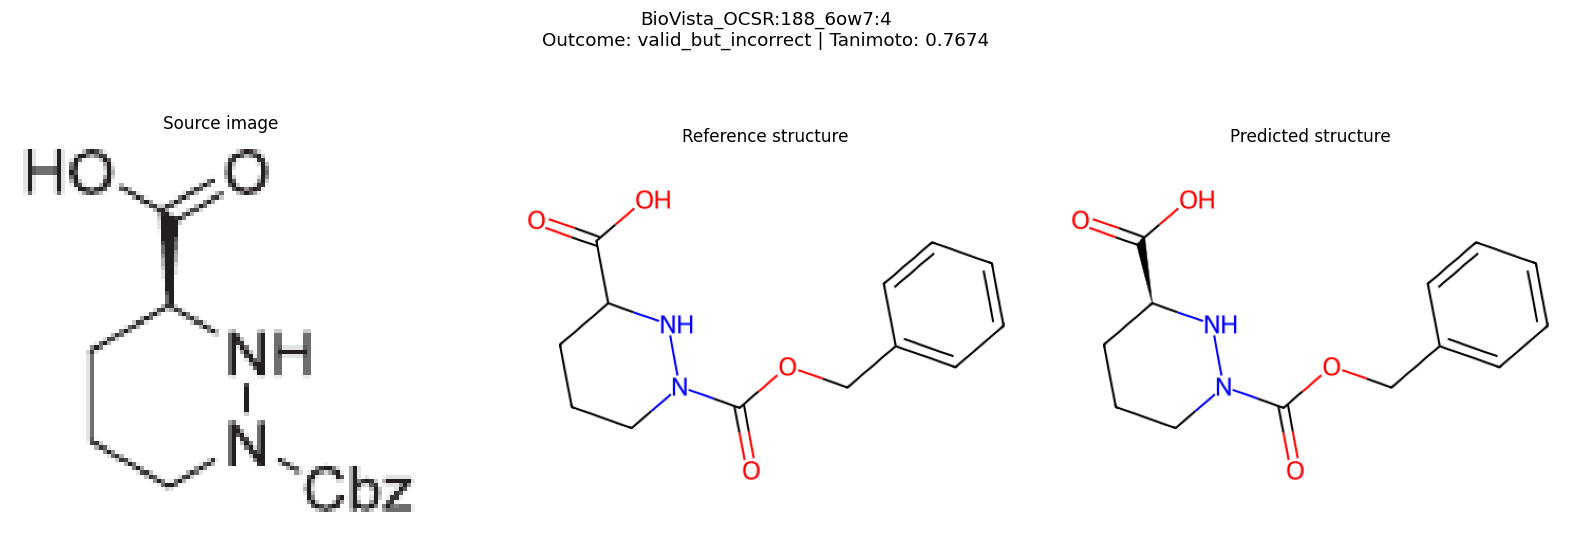

Sample ID: BioVista_OCSR:188_6ow7:4
Reference SMILES: O=C(O)C1CCCN(C(=O)OCc2ccccc2)N1
Reconstructed prediction: O=C(O)[C@@H]1CCCN(C(=O)OCc2ccccc2)N1
Raw model caption:
O=C([C@H]1NN(*)CCC1)O<sep><a>5:Cbz</a>
Saved comparison: outputs\benchmark_n100_seed42\run_20261014T055719_105367Z\error_comparisons\error_case_007.png
--------------------------------------------------------------------------------


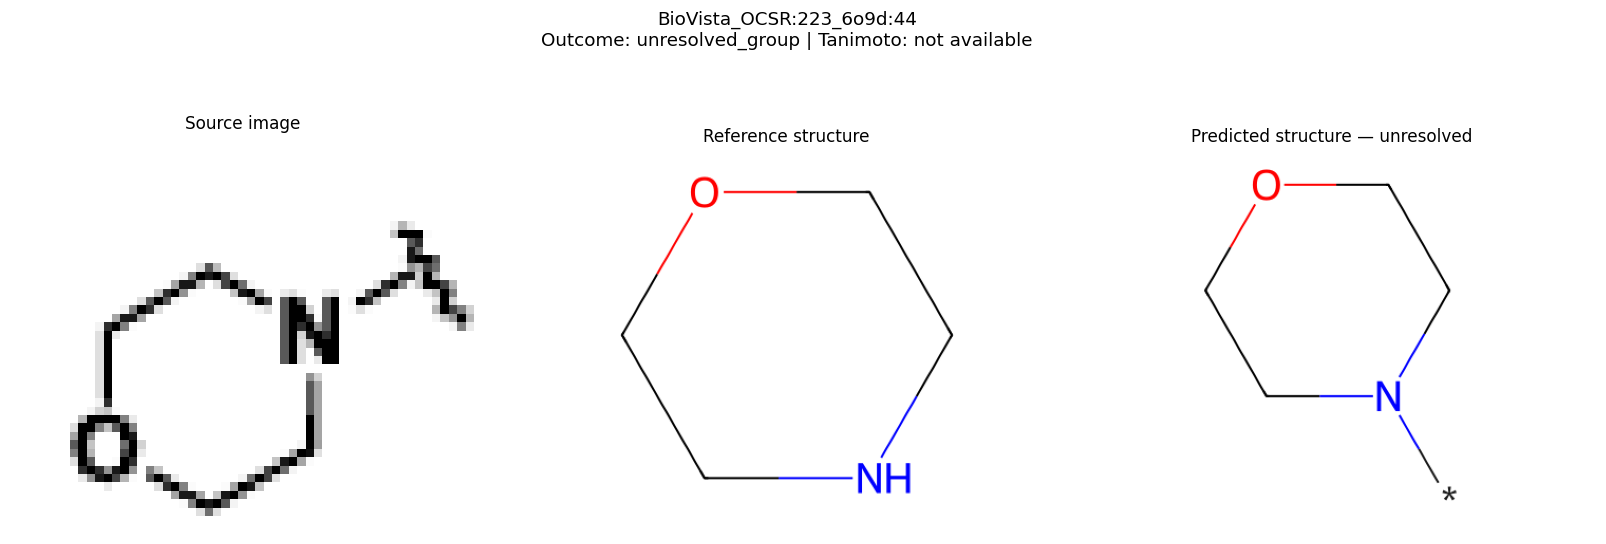

Sample ID: BioVista_OCSR:223_6o9d:44
Reference SMILES: C1COCCN1
Reconstructed prediction: *N1CCOCC1
Raw model caption:
*N1CCOCC1<sep><a>0:<dum></a>
Saved comparison: outputs\benchmark_n100_seed42\run_20261014T055719_105367Z\error_comparisons\error_case_008.png
--------------------------------------------------------------------------------


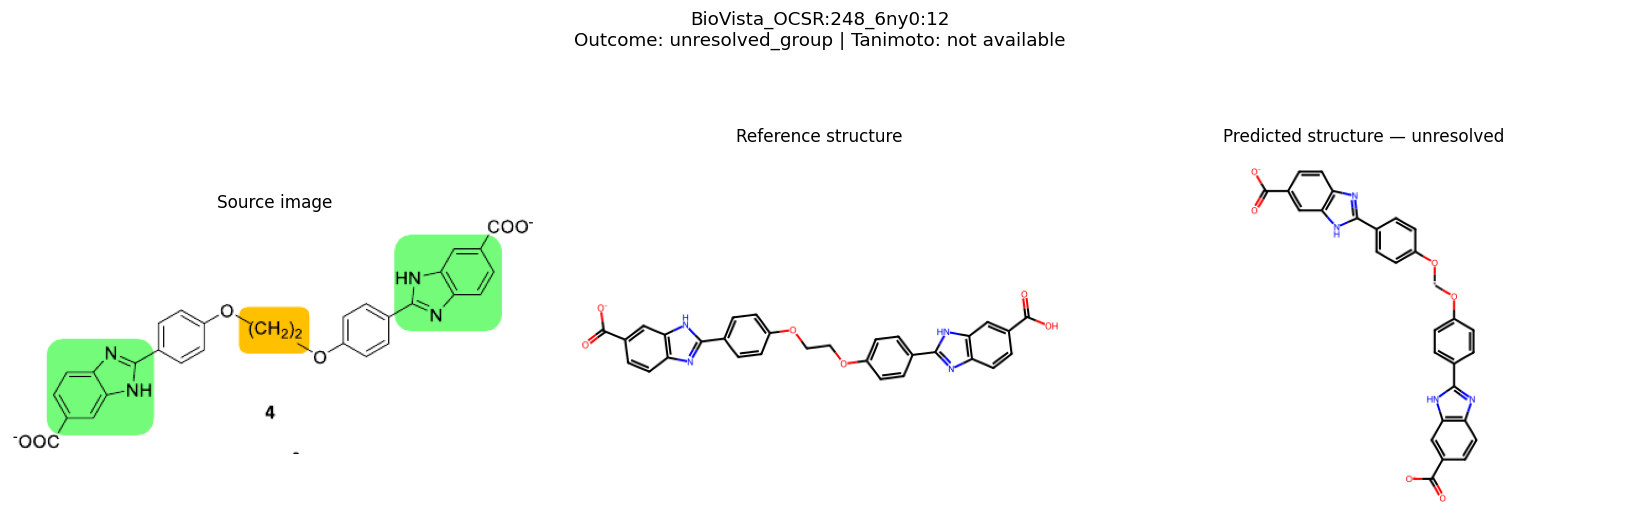

Sample ID: BioVista_OCSR:248_6ny0:12
Reference SMILES: O=C([O-])c1ccc2nc(-c3ccc(OCCOc4ccc(-c5nc6ccc(C(=O)O)cc6[nH]5)cc4)cc3)[nH]c2c1
Reconstructed prediction: C(=O)([O-])c1ccc2nc(-c3ccc(O*Oc4ccc(-c5nc6ccc(C(=O)[O-])cc6[nH]5)cc4)cc3)[nH]c2c1
Raw model caption:
C(=O)([O-])C1C=C2C(N=C(N2)C2C=CC(O*OC3C=CC(C4NC5C(=CC=C(C=5)C([O-
])=O)N=4)=CC=3)=CC=2)=CC=1<sep><a>15:CH[2]?z</a>
Saved comparison: outputs\benchmark_n100_seed42\run_20261014T055719_105367Z\error_comparisons\error_case_009.png
--------------------------------------------------------------------------------


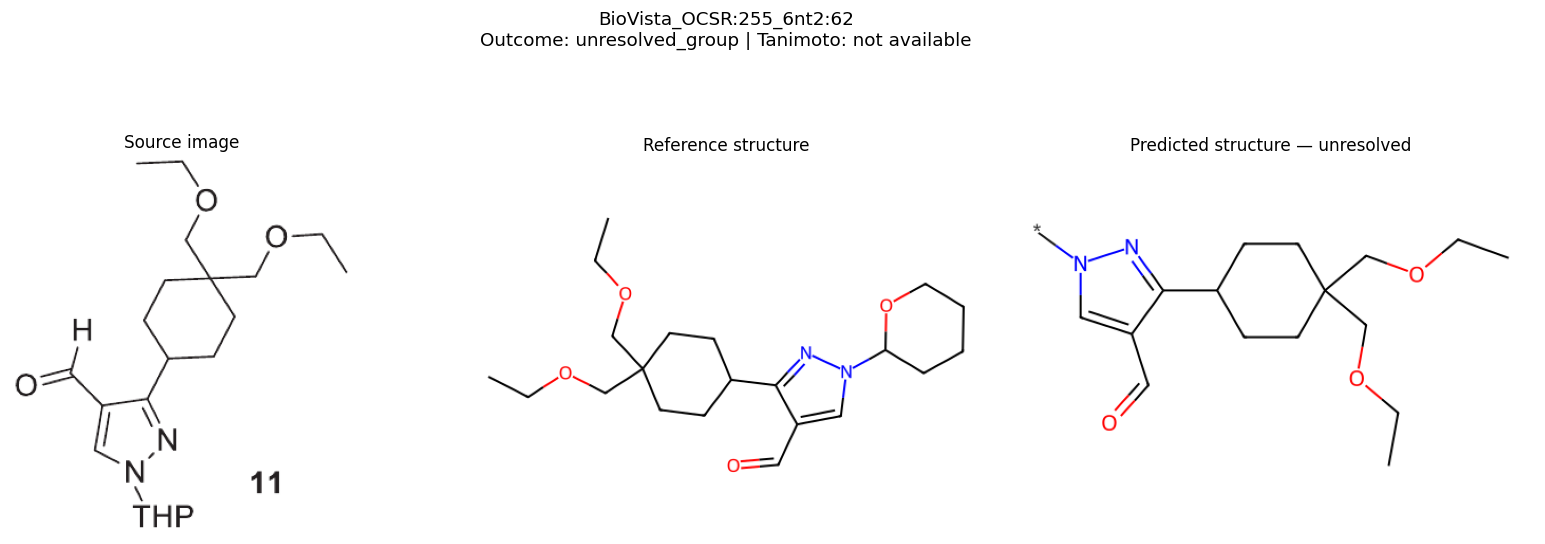

Sample ID: BioVista_OCSR:255_6nt2:62
Reference SMILES: [H]C(=O)c1cn(C2CCCCO2)nc1C1CCC(COCC)(COCC)CC1
Reconstructed prediction: CCOCC1(COCC)CCC(c2nn(*)cc2C=O)CC1
Raw model caption:
CCOCC1(CCC(C2C(C=O)=CN(*)N=2)CC1)COCC<sep><a>14:THP</a>
Saved comparison: outputs\benchmark_n100_seed42\run_20261014T055719_105367Z\error_comparisons\error_case_010.png
--------------------------------------------------------------------------------


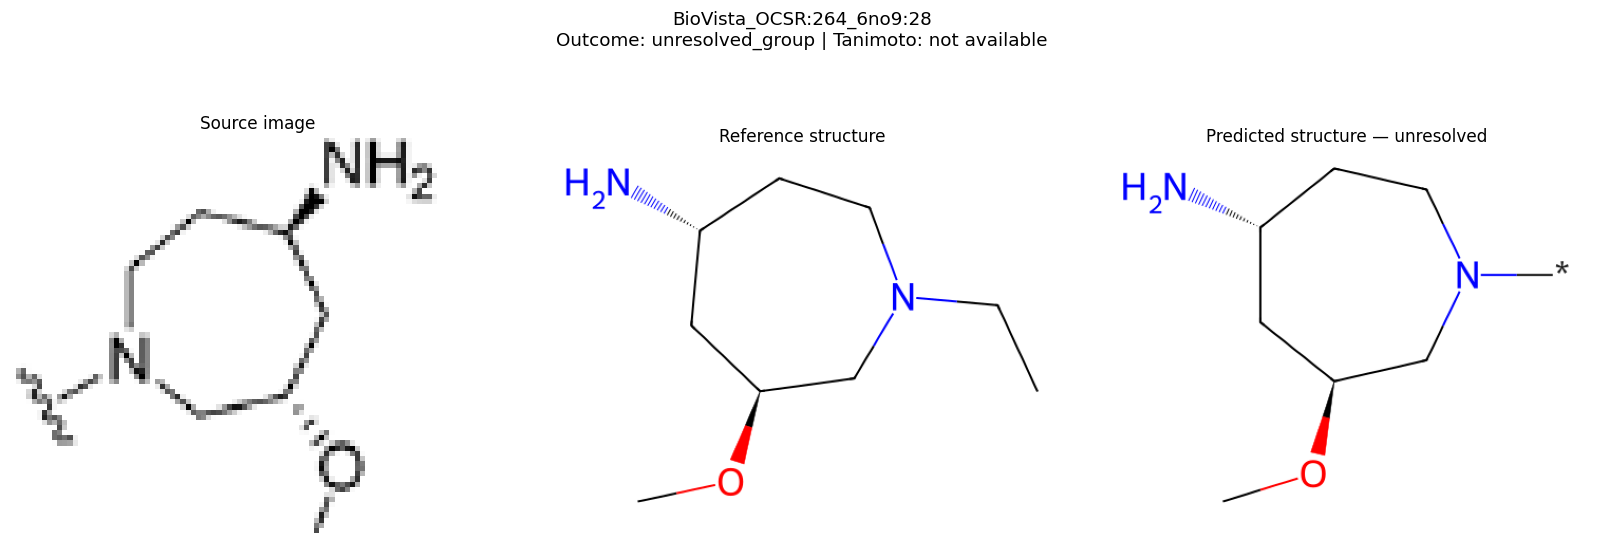

Sample ID: BioVista_OCSR:264_6no9:28
Reference SMILES: CCN1CC[C@@H](N)C[C@H](OC)C1
Reconstructed prediction: *N1CC[C@@H](N)C[C@H](OC)C1
Raw model caption:
*N1C[C@@H](OC)C[C@H](N)CC1<sep><a>0:<dum></a>
Saved comparison: outputs\benchmark_n100_seed42\run_20261014T055719_105367Z\error_comparisons\error_case_011.png
--------------------------------------------------------------------------------


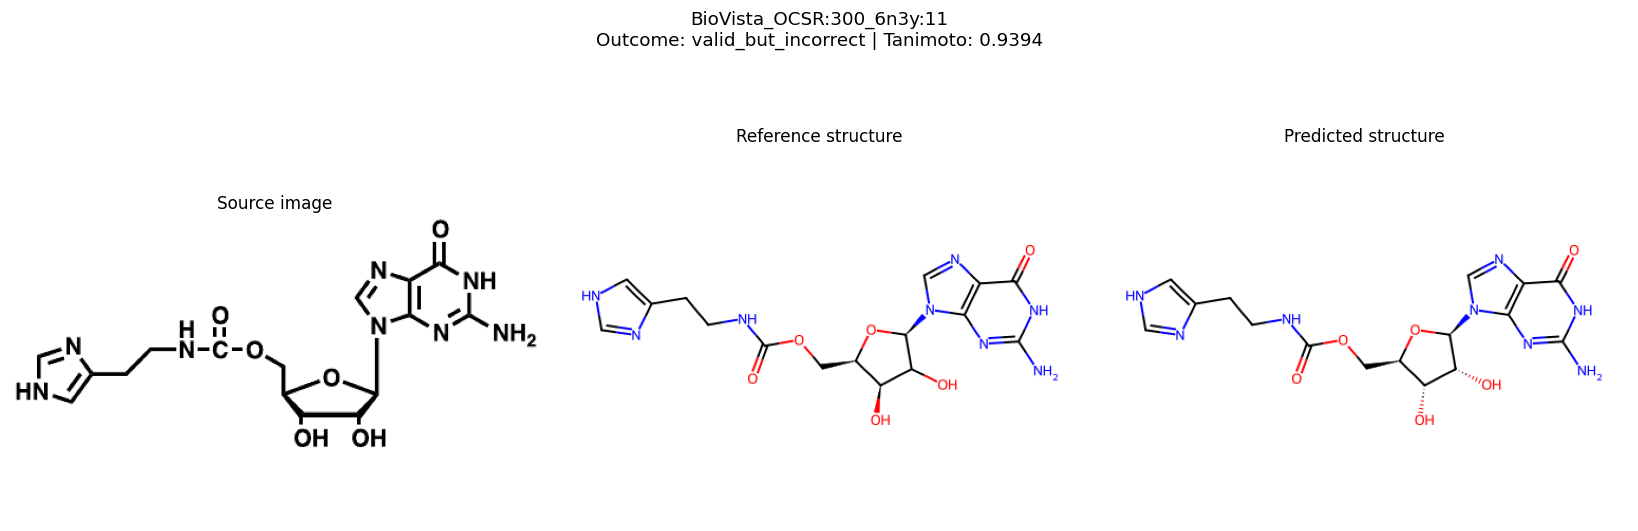

Sample ID: BioVista_OCSR:300_6n3y:11
Reference SMILES: Nc1nc2c(ncn2[C@@H]2O[C@H](COC(=O)NCCc3c[nH]cn3)[C@H](O)C2O)c(=O)[nH]1
Reconstructed prediction: Nc1nc2c(ncn2[C@@H]2O[C@H](COC(=O)NCCc3c[nH]cn3)[C@@H](O)[C@H]2O)c(=O)[nH]1
Raw model caption:
Nc1[nH]c(=O)c2nc[n]([C@H]3[C@H](O)[C@H](O)[C@@H](COC(NCCC4N=CNC=4)=O)O3)c2n1<sep>
Saved comparison: outputs\benchmark_n100_seed42\run_20261014T055719_105367Z\error_comparisons\error_case_012.png
--------------------------------------------------------------------------------


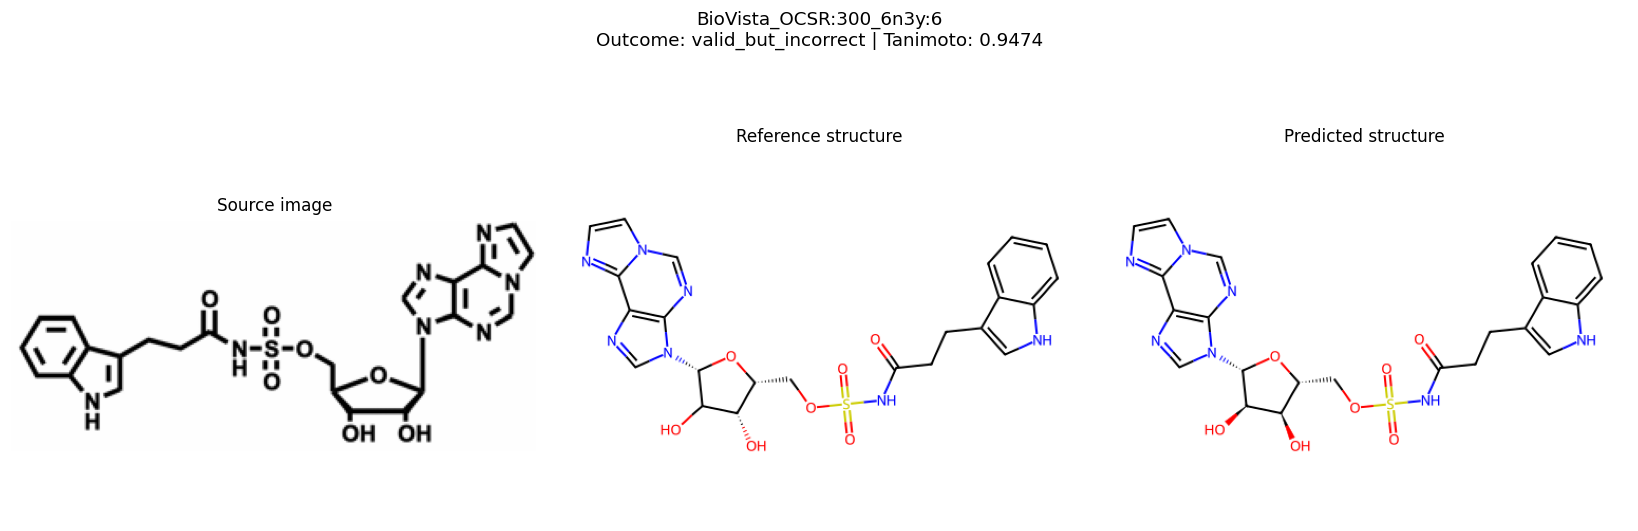

Sample ID: BioVista_OCSR:300_6n3y:6
Reference SMILES: O=C(CCc1c[nH]c2ccccc12)NS(=O)(=O)OC[C@H]1O[C@@H](n2cnc3c2ncn2ccnc32)C(O)[C@H]1O
Reconstructed prediction: O=C(CCc1c[nH]c2ccccc12)NS(=O)(=O)OC[C@H]1O[C@@H](n2cnc3c2ncn2ccnc32)[C@H](O)[C@@H]1O
Raw model caption:
O=C(CCc1c[nH]c2ccccc12)NS(=O)(=O)OC[C@H]1O[C@@H](n2cnc3c2ncn2ccnc32)[C@H](O)[C@@H]1O<
sep>
Saved comparison: outputs\benchmark_n100_seed42\run_20261014T055719_105367Z\error_comparisons\error_case_013.png
--------------------------------------------------------------------------------


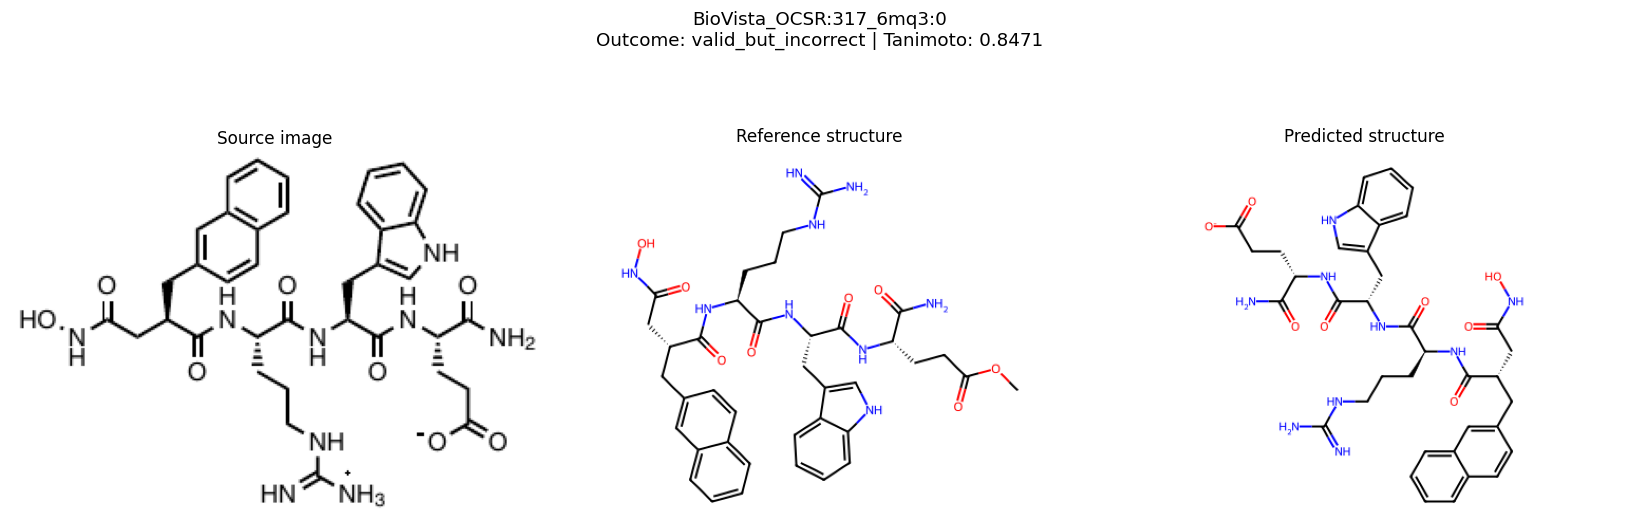

Sample ID: BioVista_OCSR:317_6mq3:0
Reference SMILES: COC(=O)CC[C@H](NC(=O)[C@H](Cc1c[nH]c2ccccc12)NC(=O)[C@H](CCCNC(=N)N)NC(=O)[C@@H](CC(=O)NO)Cc1ccc2ccccc2c1)C(N)=O
Reconstructed prediction: N=C(N)NCCC[C@H](NC(=O)[C@H](CC(=O)NO)Cc1ccc2ccccc2c1)C(=O)N[C@@H](Cc1c[nH]c2ccccc12)C(=O)N[C@@H](CCC(=O)[O-])C(N)=O
Raw model caption:
N=C(N)NCCC[C@H](NC(=O)[C@H](CC(=O)NO)Cc1ccc2ccccc2c1)C(=O)N[C@@H](Cc1c[nH]c2ccccc12)C
(=O)N[C@@H](CCC(=O)[O-])C(N)=O<sep>
Saved comparison: outputs\benchmark_n100_seed42\run_20261014T055719_105367Z\error_comparisons\error_case_014.png
--------------------------------------------------------------------------------


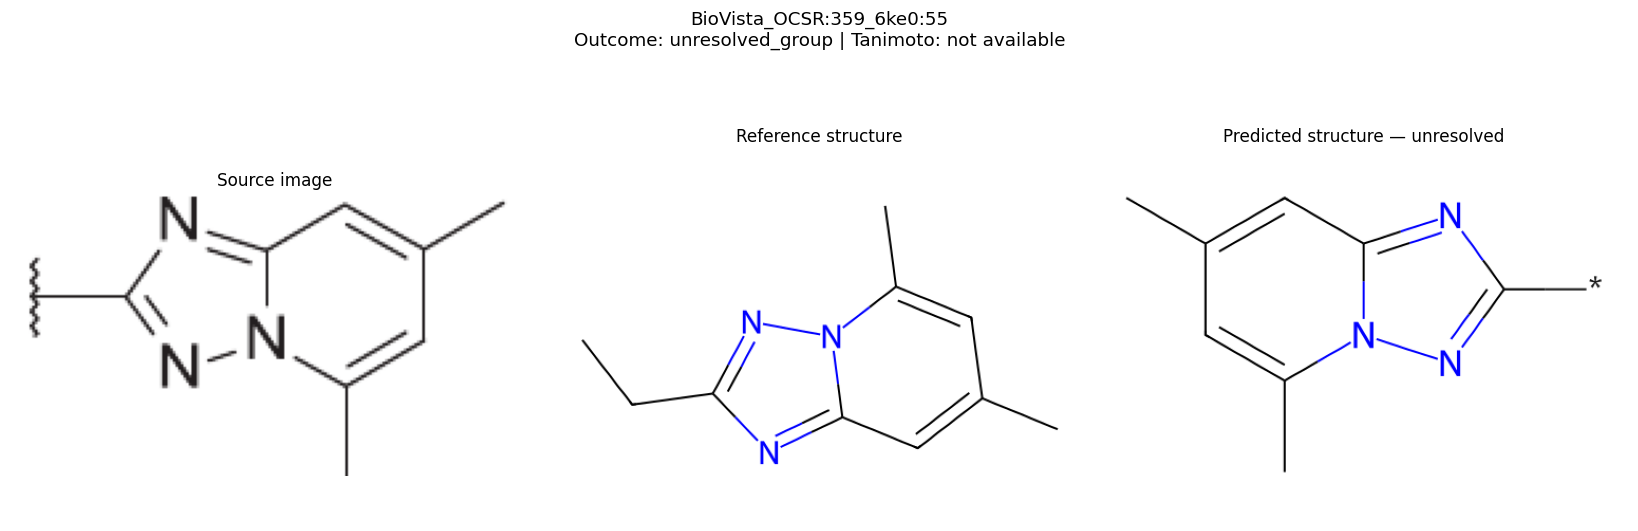

Sample ID: BioVista_OCSR:359_6ke0:55
Reference SMILES: CCc1nc2cc(C)cc(C)n2n1
Reconstructed prediction: *c1nc2cc(C)cc(C)n2n1
Raw model caption:
*C1=NN2C(C=C(C=C2C)C)=N1<sep><a>0:<dum></a>
Saved comparison: outputs\benchmark_n100_seed42\run_20261014T055719_105367Z\error_comparisons\error_case_015.png
--------------------------------------------------------------------------------


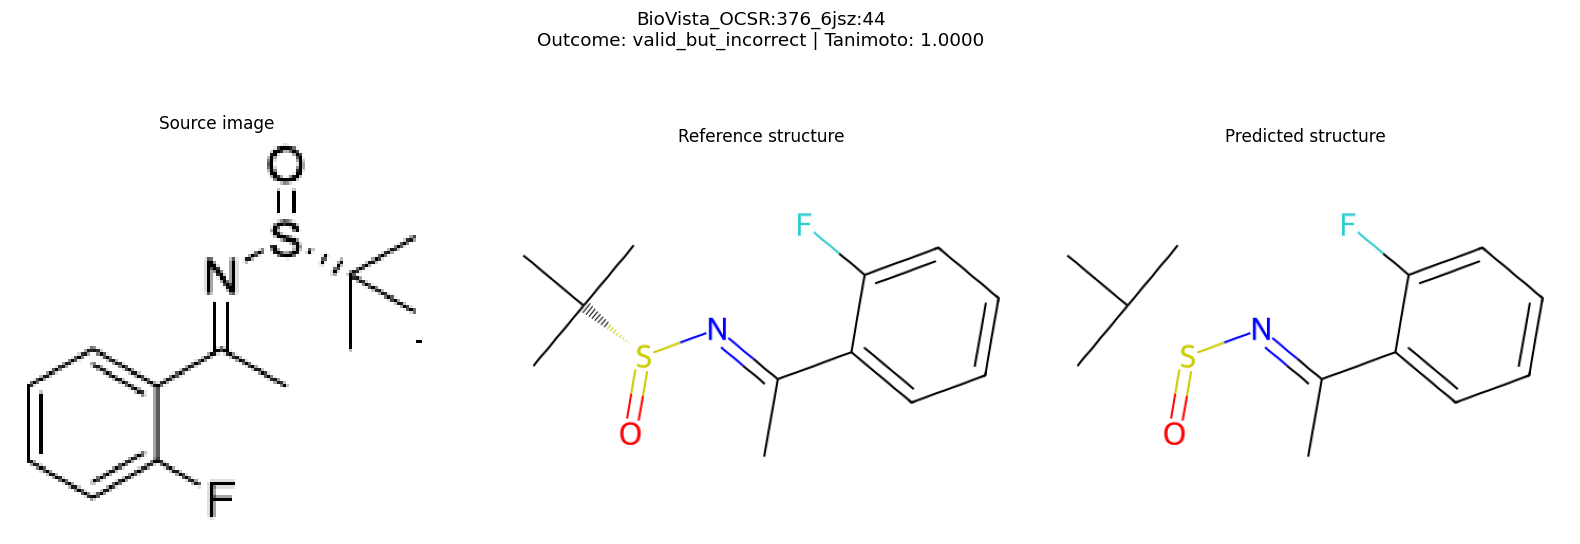

Sample ID: BioVista_OCSR:376_6jsz:44
Reference SMILES: C/C(=N\[S@](=O)C(C)(C)C)c1ccccc1F
Reconstructed prediction: C/C(=N\[S@@](=O)C(C)(C)C)c1ccccc1F
Raw model caption:
C/C(=N\[S@@](=O)C(C)(C)C)c1ccccc1F<sep>
Saved comparison: outputs\benchmark_n100_seed42\run_20261014T055719_105367Z\error_comparisons\error_case_016.png
--------------------------------------------------------------------------------


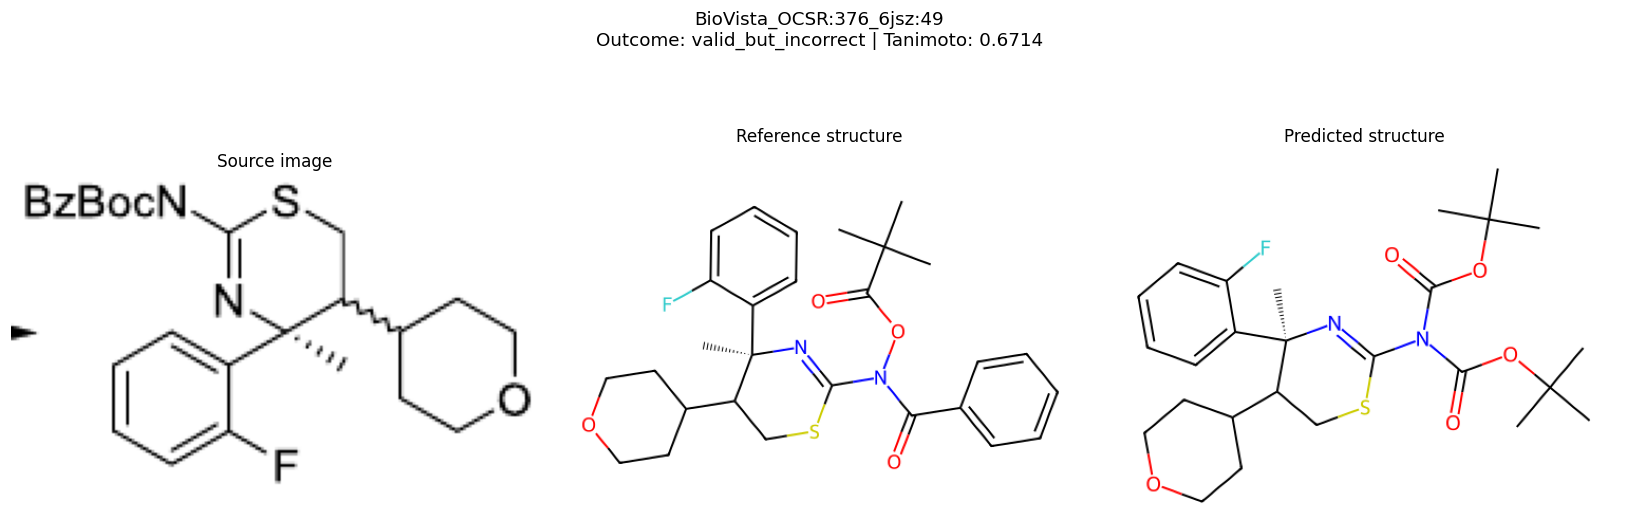

Sample ID: BioVista_OCSR:376_6jsz:49
Reference SMILES: CC(C)(C)C(=O)ON(C(=O)c1ccccc1)C1=N[C@](C)(c2ccccc2F)C(C2CCOCC2)CS1
Reconstructed prediction: N(C(=O)OC(C)(C)C)(C(=O)OC(C)(C)C)C1=N[C@](C)(c2ccccc2F)C(C2CCOCC2)CS1
Raw model caption:
N(C1=N[C@](C)(c2ccccc2F)C(C2CCOCC2)CS1)(C(OC(C)(C)C)=O)C(=O)OC(C)(C)C<sep>
Saved comparison: outputs\benchmark_n100_seed42\run_20261014T055719_105367Z\error_comparisons\error_case_017.png
--------------------------------------------------------------------------------


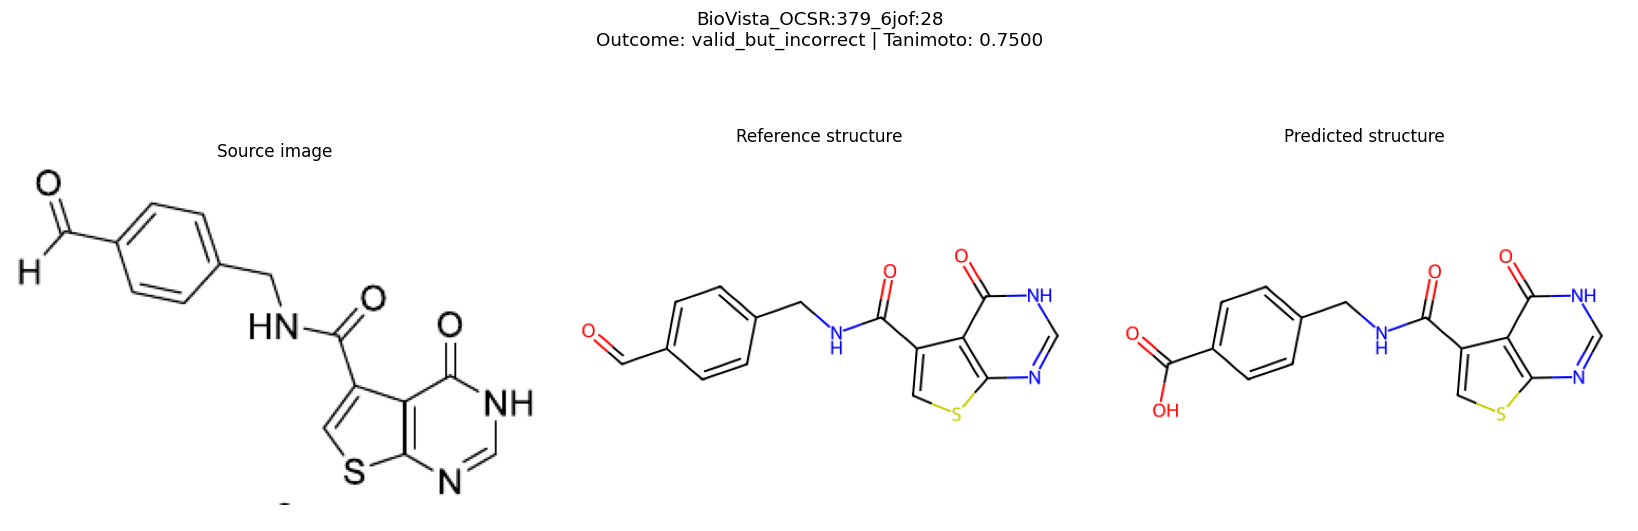

Sample ID: BioVista_OCSR:379_6jof:28
Reference SMILES: O=Cc1ccc(CNC(=O)c2csc3nc[nH]c(=O)c23)cc1
Reconstructed prediction: O=C(O)c1ccc(CNC(=O)c2csc3nc[nH]c(=O)c23)cc1
Raw model caption:
O=C(O)c1ccc(CNC(=O)c2csc3nc[nH]c(=O)c23)cc1<sep>
Saved comparison: outputs\benchmark_n100_seed42\run_20261014T055719_105367Z\error_comparisons\error_case_018.png
--------------------------------------------------------------------------------


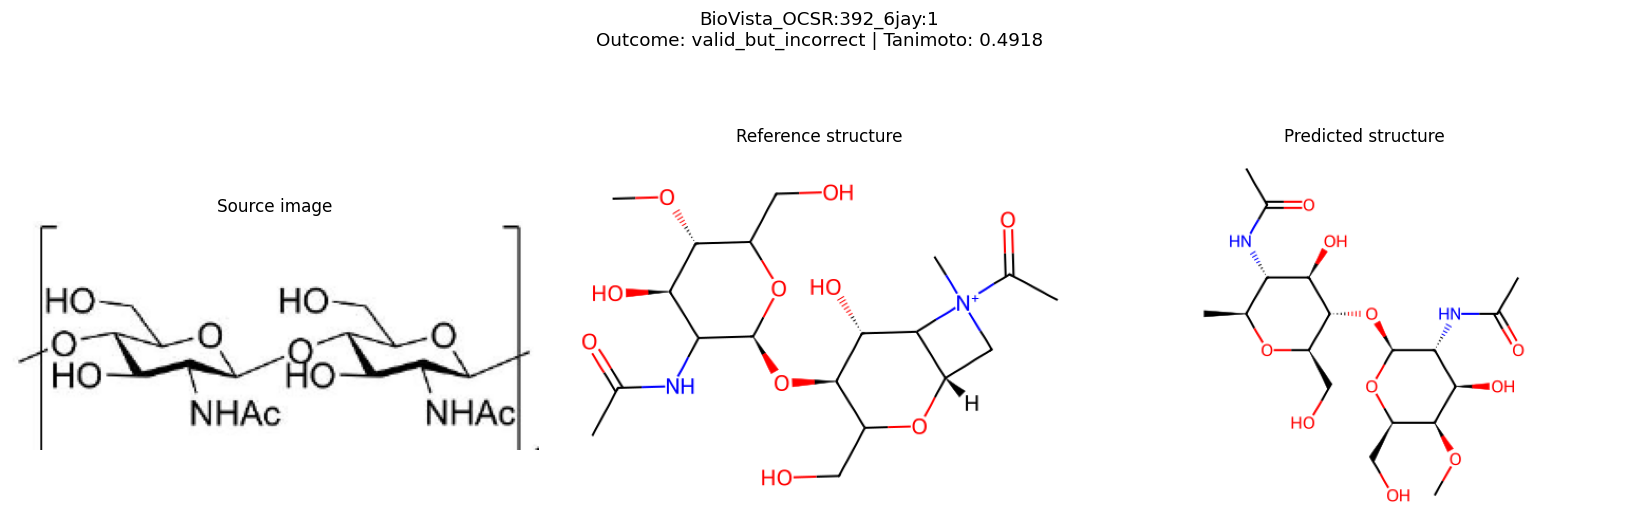

Sample ID: BioVista_OCSR:392_6jay:1
Reference SMILES: CO[C@@H]1C(CO)O[C@@H](O[C@@H]2C(CO)O[C@H]3C[N+](C)(C(C)=O)C3[C@H]2O)C(NC(C)=O)[C@H]1O
Reconstructed prediction: [C@@H]1(OC)[C@H](O)[C@@H](NC(C)=O)[C@H](O[C@H]2[C@H](O)[C@@H](NC(C)=O)[C@H](C)O[C@@H]2CO)O[C@@H]1CO
Raw model caption:
[C@@H]1([C@@H](CO)O[C@@H](O[C@@H]2[C@@H](CO)O[C@@H](C)[C@H](NC(C)=O)[C@H]2O)[C@H](NC(
C)=O)[C@H]1O)OC<sep>
Saved comparison: outputs\benchmark_n100_seed42\run_20261014T055719_105367Z\error_comparisons\error_case_019.png
--------------------------------------------------------------------------------


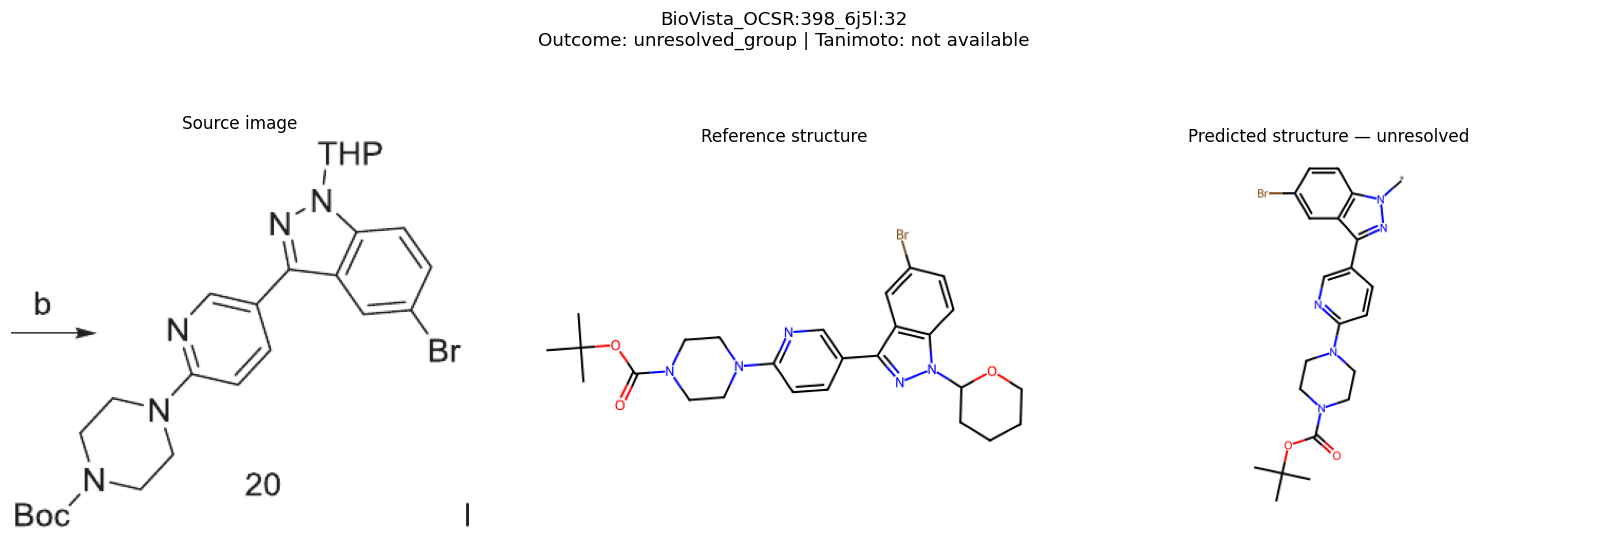

Sample ID: BioVista_OCSR:398_6j5l:32
Reference SMILES: CC(C)(C)OC(=O)N1CCN(c2ccc(-c3nn(C4CCCCO4)c4ccc(Br)cc34)cn2)CC1
Reconstructed prediction: N1(C(=O)OC(C)(C)C)CCN(c2ccc(-c3nn(*)c4ccc(Br)cc34)cn2)CC1
Raw model caption:
*N1CCN(C2N=CC(C3C4C(=CC=C(C=4)Br)N(*)N=3)=CC=2)CC1<sep><a>0:Boc</a><a>18:THP</a>
Saved comparison: outputs\benchmark_n100_seed42\run_20261014T055719_105367Z\error_comparisons\error_case_020.png
--------------------------------------------------------------------------------


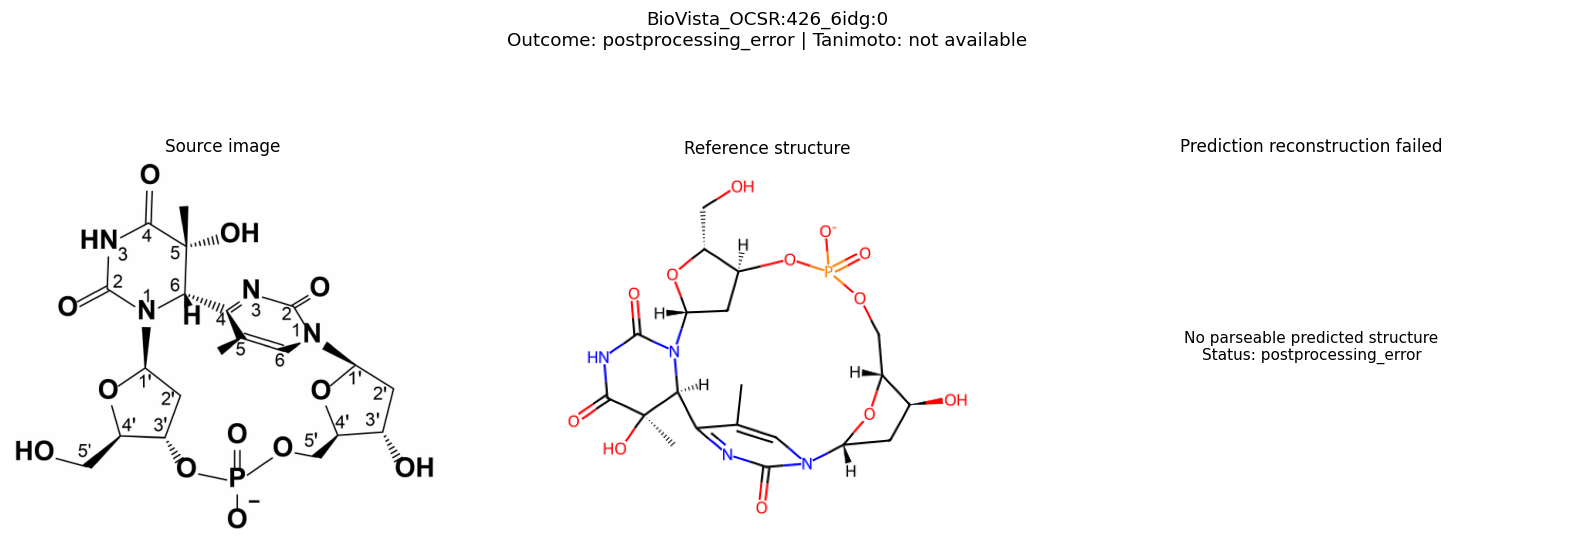

Sample ID: BioVista_OCSR:426_6idg:0
Reference SMILES: Cc1cn2c(=O)nc1[C@@H]1N(C(=O)NC(=O)[C@]1(C)O)[C@H]1C[C@H](OP(=O)([O-])OC[C@H]3O[C@@H]2C[C@@H]3O)[C@@H](CO)O1
Reconstructed prediction: 
Raw model caption:
C[C@@]1(O)C(=O)NC(=O)N2[C@H]3C[C@H](OP(=O)([O-
])OC[C@H]4O[C@@H](C[C@H]4O)N4C(=O)N[C@@](C(=C4)C)([C@H]12)C1=NC(=O)N([C@@H]2O[C@H](CO
)[C@@H](O)[C@H](CO)O2)C2C(=CC(=N2)C)N=1<sep>
Decoding error: The official decoder could not reconstruct the caption.
Saved comparison: outputs\benchmark_n100_seed42\run_20261014T055719_105367Z\error_comparisons\error_case_021.png
--------------------------------------------------------------------------------


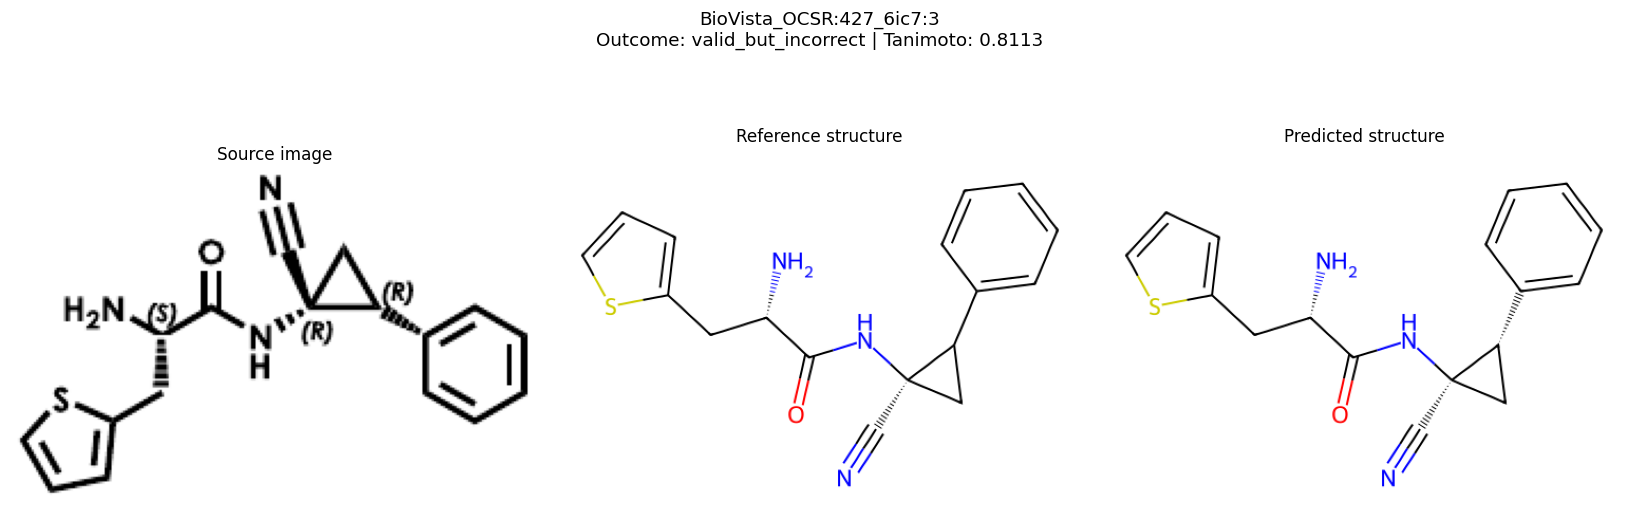

Sample ID: BioVista_OCSR:427_6ic7:3
Reference SMILES: N#C[C@@]1(NC(=O)[C@@H](N)Cc2cccs2)CC1c1ccccc1
Reconstructed prediction: N#C[C@@]1(NC(=O)[C@@H](N)Cc2cccs2)C[C@H]1c1ccccc1
Raw model caption:
N#C[C@@]1(NC(=O)[C@@H](N)Cc2cccs2)C[C@H]1c1ccccc1<sep>
Saved comparison: outputs\benchmark_n100_seed42\run_20261014T055719_105367Z\error_comparisons\error_case_022.png
--------------------------------------------------------------------------------


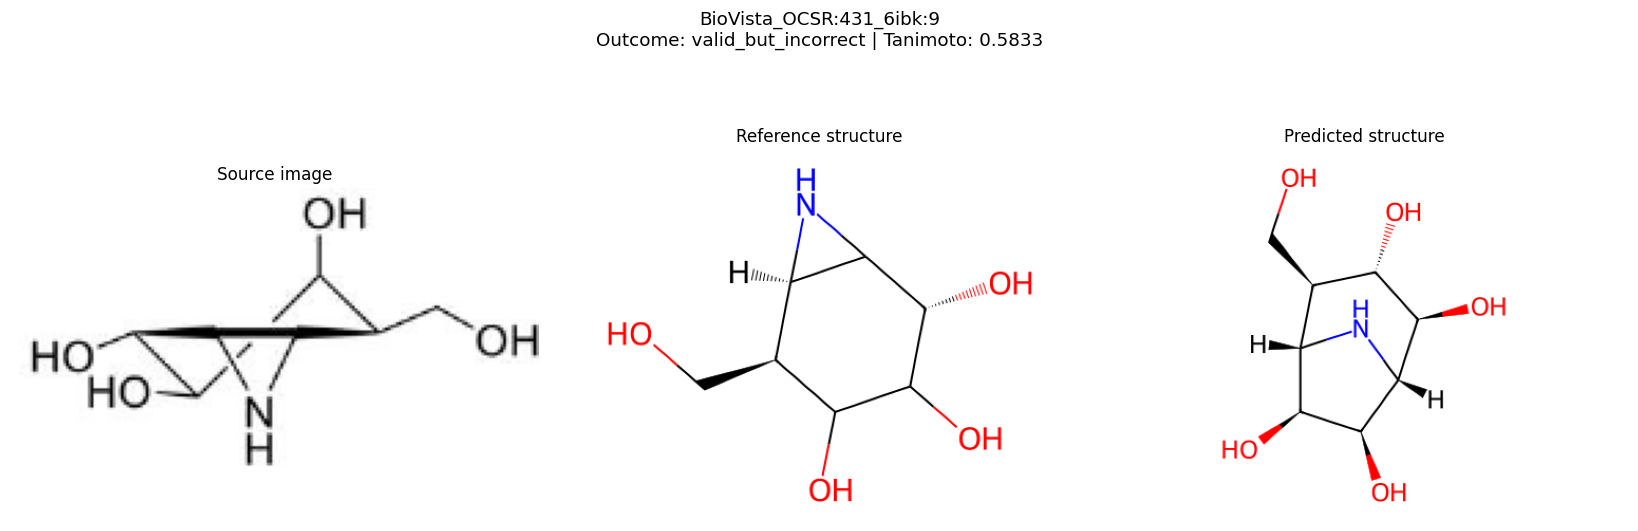

Sample ID: BioVista_OCSR:431_6ibk:9
Reference SMILES: OC[C@@H]1C(O)C(O)[C@@H](O)C2N[C@@H]21
Reconstructed prediction: OC[C@H]1[C@H](O)[C@@H](O)[C@H]2N[C@@H]1[C@H](O)[C@@H]2O
Raw model caption:
OC[C@@H]1[C@@H]2N[C@@H]([C@H]([C@H]2O)O)[C@H](O)[C@H]1O<sep>
Saved comparison: outputs\benchmark_n100_seed42\run_20261014T055719_105367Z\error_comparisons\error_case_023.png
--------------------------------------------------------------------------------


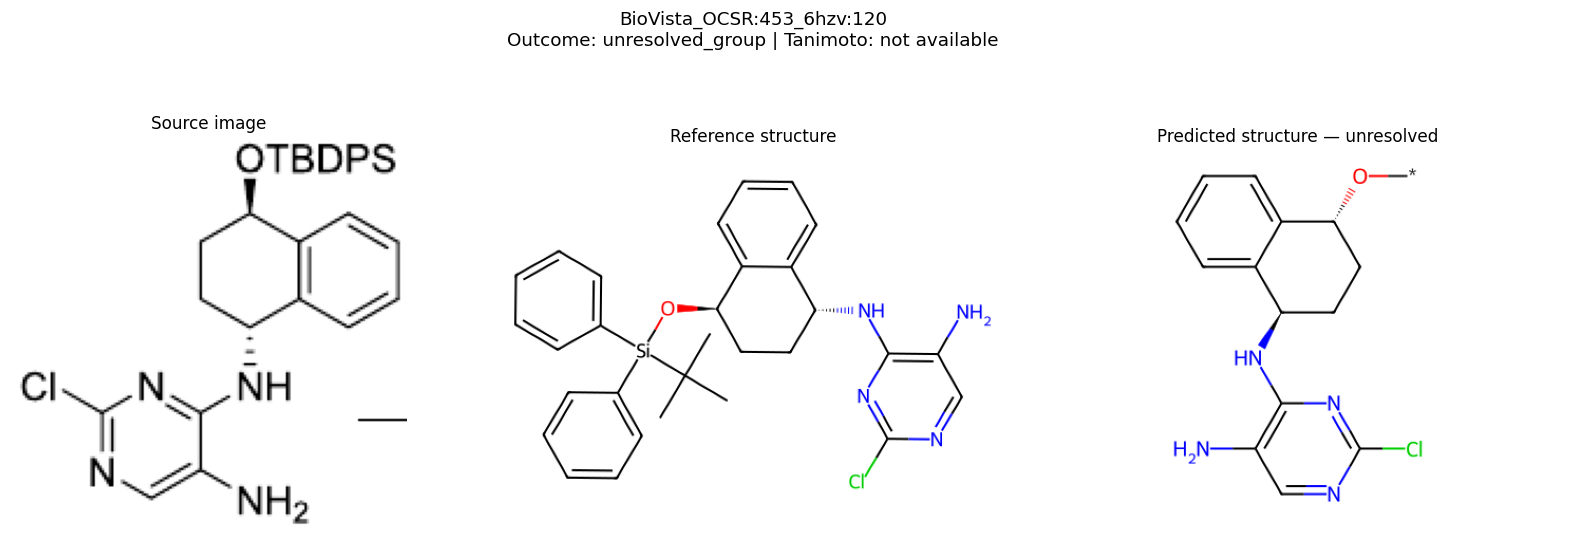

Sample ID: BioVista_OCSR:453_6hzv:120
Reference SMILES: CC(C)(C)[Si](O[C@@H]1CC[C@@H](Nc2nc(Cl)ncc2N)c2ccccc21)(c1ccccc1)c1ccccc1
Reconstructed prediction: Nc1cnc(Cl)nc1N[C@@H]1CC[C@@H](O*)c2ccccc21
Raw model caption:
NC1C(N[C@H]2C3C(=CC=CC=3)[C@H](O*)CC2)=NC(Cl)=NC=1<sep><a>13:TBDPS</a>
Saved comparison: outputs\benchmark_n100_seed42\run_20261014T055719_105367Z\error_comparisons\error_case_024.png
--------------------------------------------------------------------------------


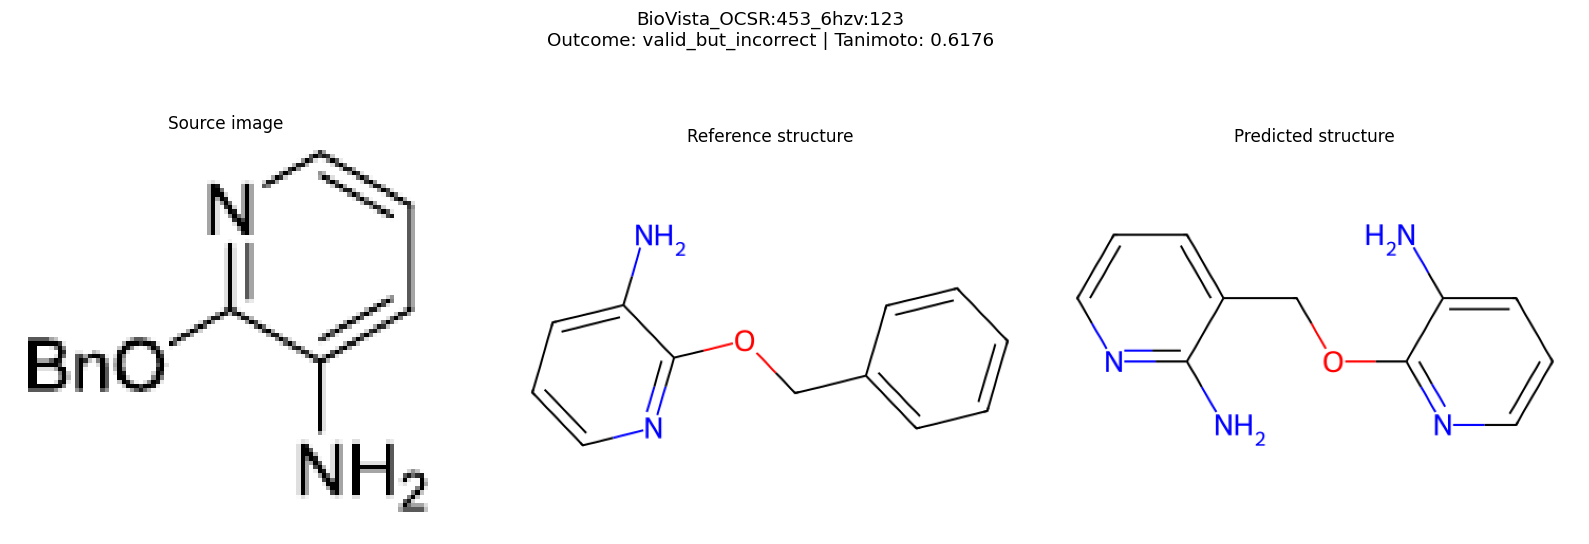

Sample ID: BioVista_OCSR:453_6hzv:123
Reference SMILES: Nc1cccnc1OCc1ccccc1
Reconstructed prediction: O(Cc1cccnc1N)c1ncccc1N
Raw model caption:
O(c1ncccc1N)Cc1cccnc1N<sep>
Saved comparison: outputs\benchmark_n100_seed42\run_20261014T055719_105367Z\error_comparisons\error_case_025.png
--------------------------------------------------------------------------------


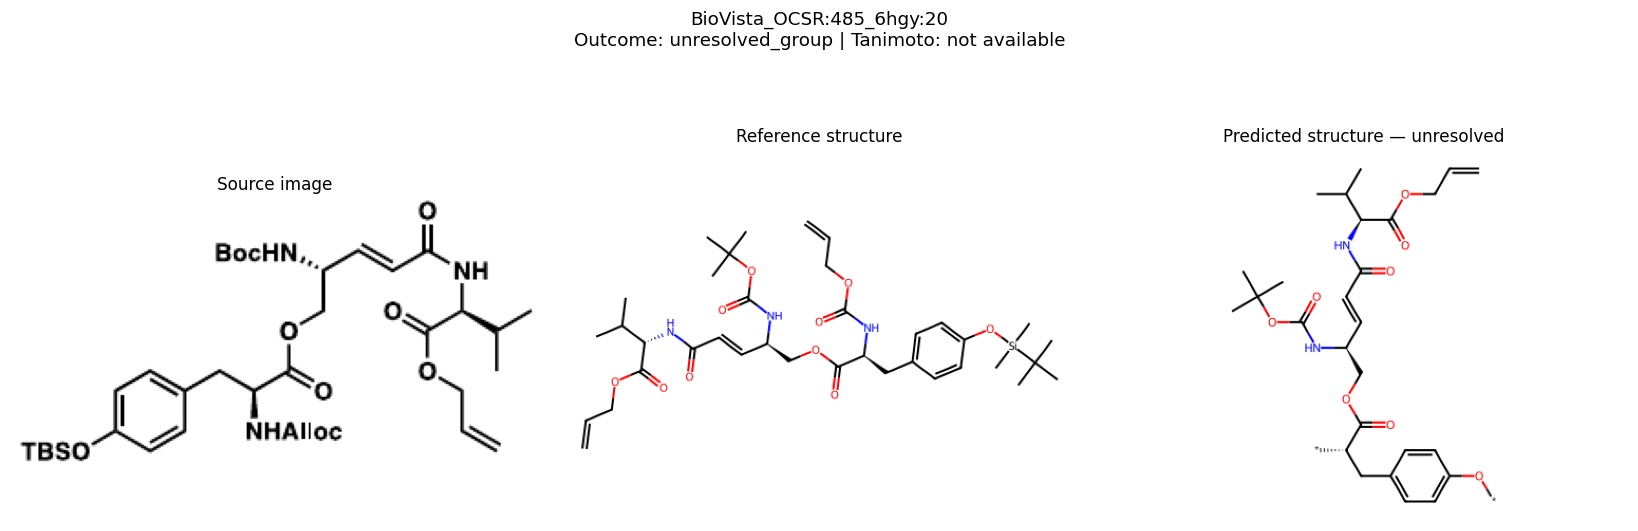

Sample ID: BioVista_OCSR:485_6hgy:20
Reference SMILES: C=CCOC(=O)N[C@@H](Cc1ccc(O[Si](C)(C)C(C)(C)C)cc1)C(=O)OC[C@@H](/C=C/C(=O)N[C@H](C(=O)OCC=C)C(C)C)NC(=O)OC(C)(C)C
Reconstructed prediction: *Oc1ccc(C[C@H](*)C(=O)OC[C@H](/C=C/C(=O)N[C@H](C(=O)OCC=C)C(C)C)NC(=O)OC(C)(C)C)cc1
Raw model caption:
*OC1=CC=C(C[C@H](*)C(=O)OC[C@H](*)/C=C/C(=O)N[C@H](C(=O)OCC=C)C(C)C)C=C1<sep><a>0:TBS
</a><a>8:NHAlloc</a><a>14:NHBoc</a>
Saved comparison: outputs\benchmark_n100_seed42\run_20261014T055719_105367Z\error_comparisons\error_case_026.png
--------------------------------------------------------------------------------


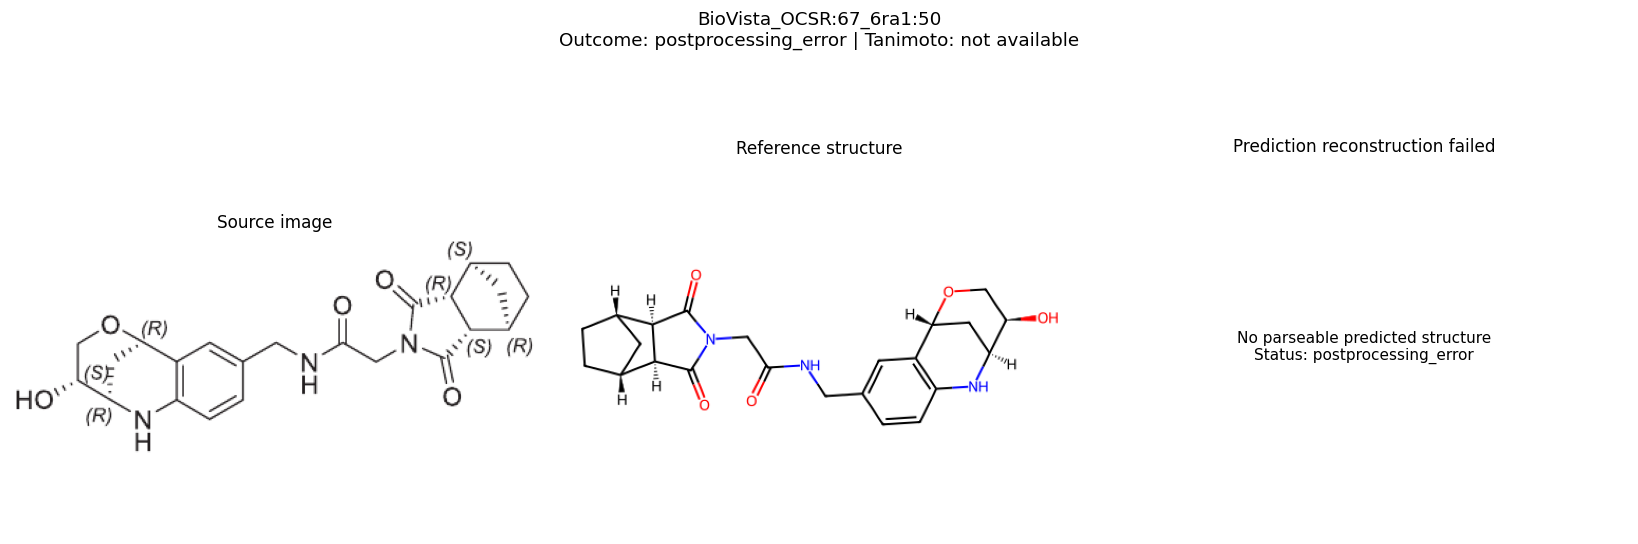

Sample ID: BioVista_OCSR:67_6ra1:50
Reference SMILES: O=C(CN1C(=O)[C@@H]2[C@H]3CC[C@H](C3)[C@@H]2C1=O)NCc1ccc2c(c1)[C@H]1C[C@H](N2)[C@H](O)CO1
Reconstructed prediction: 
Raw model caption:
O=C(NCC1C=C2[C@@]3([H])[C@@](NC2=CC=1)([C@H](O)CO3)[C@H](O)CO3)CN1C(=O)[C@H]2[C@H]3C[
C@@H](C3)[C@H]2C1=O<sep>
Decoding error: The official decoder could not reconstruct the caption.
Saved comparison: outputs\benchmark_n100_seed42\run_20261014T055719_105367Z\error_comparisons\error_case_027.png
--------------------------------------------------------------------------------


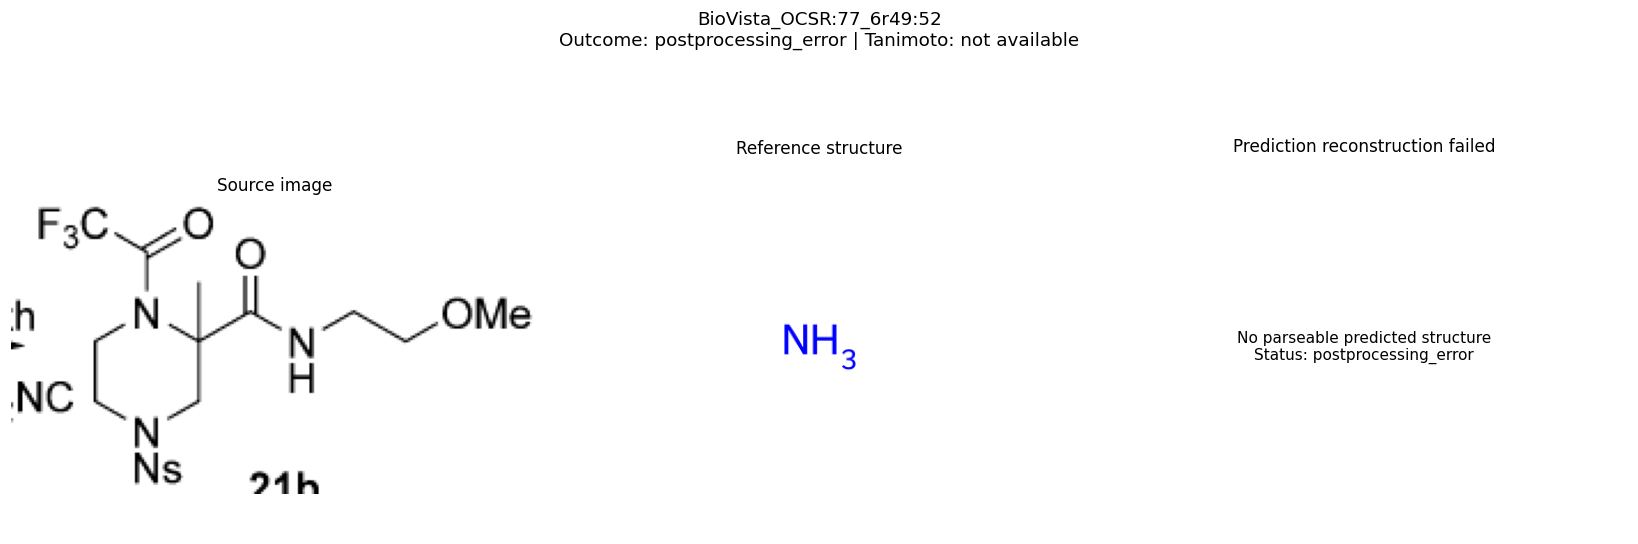

Sample ID: BioVista_OCSR:77_6r49:52
Reference SMILES: N
Reconstructed prediction: 
Raw model caption:
C(C(=O)N1CCN(N=S(C#N)(=O)=O)CC1(C)C(=O)NCCOC)(F)(F)F<sep>
Decoding error: The official decoder could not reconstruct the caption.
Saved comparison: outputs\benchmark_n100_seed42\run_20261014T055719_105367Z\error_comparisons\error_case_028.png
--------------------------------------------------------------------------------


In [119]:
# Compare source images, reference structures, and unsuccessful predictions.
import textwrap
from rdkit.Chem import Draw

error_cases = evaluated.loc[
    ~evaluated["exact_match"]
].copy()

COMPARISON_DIR = RUN_DIR / "error_comparisons"
COMPARISON_DIR.mkdir(parents=True, exist_ok=True)


def parse_structure(smiles):
    """Parse a nonempty SMILES string without printing RDKit warnings."""
    if not isinstance(smiles, str) or not smiles.strip():
        return None

    try:
        with rdBase.BlockLogs():
            return Chem.MolFromSmiles(smiles)
    except Exception:
        return None


def wrap_caption(value, width=85):
    """Wrap long model captions for readable figure annotations."""
    if not isinstance(value, str) or not value:
        return "(empty)"
    return "\n".join(
        textwrap.wrap(value, width=width, break_long_words=True)
    )


print("Cases without an exact match:", len(error_cases))

for case_number, (_, row) in enumerate(
    error_cases.iterrows(), start=1
):
    reference_molecule = parse_structure(row["ground_truth_smiles"])
    prediction_molecule = parse_structure(row["predicted_smiles"])

    # Align the predicted drawing to the reference when a shared core exists.
    # Coordinate changes affect visualization only, not chemical evaluation.
    alignment_note = ""
    if reference_molecule is not None:
        from rdkit.Chem import rdDepictor

        rdDepictor.Compute2DCoords(reference_molecule)

        if prediction_molecule is not None:
            try:
                rdDepictor.GenerateDepictionMatching2DStructure(
                    prediction_molecule,
                    reference_molecule,
                    acceptFailure=True
                )
            except Exception:
                rdDepictor.Compute2DCoords(prediction_molecule)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # Panel 1: original recognition input.
    image_bgr = cv2.imread(str(Path(row["image_path"])))

    if image_bgr is None:
        axes[0].text(
            0.5, 0.5, "Source image unavailable",
            ha="center", va="center",
            transform=axes[0].transAxes
        )
    else:
        axes[0].imshow(
            cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
        )

    axes[0].set_title("Source image")

    # Panel 2: supplied reference structure.
    if reference_molecule is not None:
        axes[1].imshow(
            Draw.MolToImage(reference_molecule, size=(500, 350))
        )
    else:
        axes[1].text(
            0.5, 0.5, "Reference cannot be parsed",
            ha="center", va="center",
            transform=axes[1].transAxes
        )

    axes[1].set_title("Reference structure")

    # Panel 3: reconstructed prediction, including unresolved dummy atoms.
    if prediction_molecule is not None:
        axes[2].imshow(
            Draw.MolToImage(prediction_molecule, size=(500, 350))
        )
        prediction_title = (
            "Predicted structure"
            if row["valid_prediction"]
            else "Predicted structure — unresolved"
        )
    else:
        axes[2].text(
            0.5, 0.5,
            "No parseable predicted structure\n"
            f"Status: {row['evaluation_status']}",
            ha="center", va="center",
            transform=axes[2].transAxes
        )
        prediction_title = "Prediction reconstruction failed"

    axes[2].set_title(prediction_title)

    for axis in axes:
        axis.axis("off")

    similarity = row["tanimoto"]
    similarity_label = (
        f"{similarity:.4f}"
        if pd.notna(similarity)
        else "not available"
    )

    fig.suptitle(
        f"{row['sample_id']}\n"
        f"Outcome: {row['evaluation_status']} | "
        f"Tanimoto: {similarity_label}",
        fontsize=12
    )
    fig.tight_layout(rect=[0, 0, 1, 0.88])

    figure_path = (
        COMPARISON_DIR / f"error_case_{case_number:03d}.png"
    )
    fig.savefig(figure_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    # Preserve exact strings for inspection of syntax and chemical differences.
    print("Sample ID:", row["sample_id"])
    print("Reference SMILES:", row["ground_truth_smiles"])
    print("Reconstructed prediction:", row["predicted_smiles"])
    print("Raw model caption:")
    print(wrap_caption(row["raw_predicted_smiles"]))

    decoding_error = row.get("postprocessing_error", "")
    if isinstance(decoding_error, str) and decoding_error:
        print("Decoding error:", decoding_error)

    print("Saved comparison:", figure_path)
    print("-" * 80)

## 11. Dataset-specific summaries and visualization
Summarize the BioVista subset separately from the XN exploratory and pilot samples. Exact-match accuracy and complete valid-output rate use all samples in each group. Report valid-only and failure-penalized mean Tanimoto, inference timing, and outcome counts.

The public figure shows recognition rates and every observed outcome category. The four manually selected XN samples provide descriptive pipeline checks and do not establish representative performance across scientific papers.

      dataset                    sample_usage  n_samples  n_valid_predictions  n_exact_matches  exact_match_accuracy  valid_output_rate  mean_tanimoto_valid_only  mean_tanimoto_failure_penalized  mean_seconds_per_sample  median_seconds_per_sample  total_inference_seconds  n_inference_errors
BioVista_OCSR fixed_public_nonwildcard_subset        100                   87               72                  0.72               0.87                    0.9607                           0.8358                   1.2087                     1.1030                 120.8737                   0
           XN                     exploratory          3                    3                3                  1.00               1.00                    1.0000                           1.0000                   1.3399                     1.2927                   4.0197                   0
           XN                           pilot          1                    1                1                  1.00        

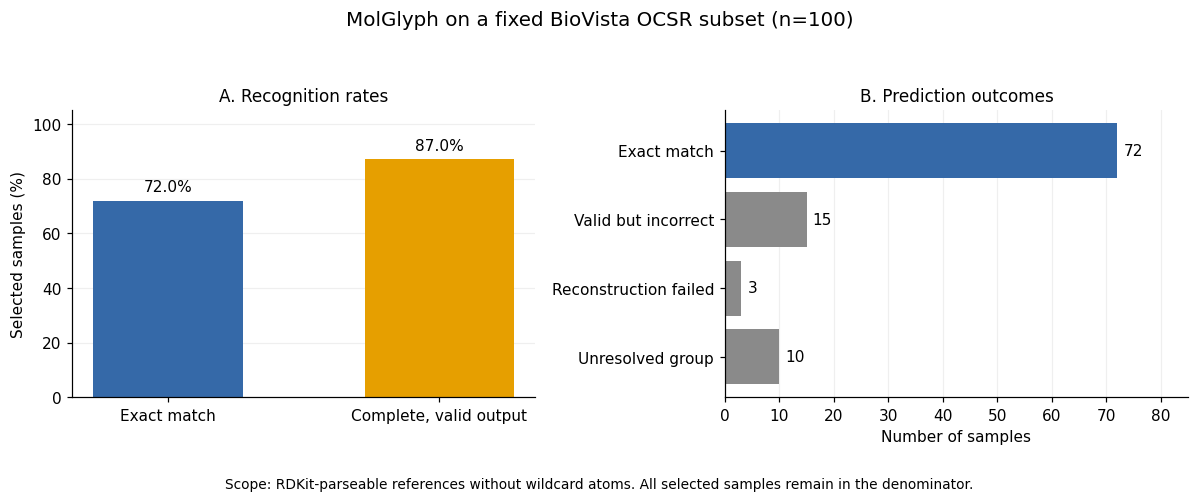


XN manually selected samples:
sample_usage  n_samples  n_exact_matches  exact_match_accuracy  valid_output_rate
 exploratory          3                3                   1.0                1.0
       pilot          1                1                   1.0                1.0

The XN samples are a small exploratory set, not evidence of general performance across scientific papers.


In [113]:
summary_records = []

for (dataset, usage), group in evaluated.groupby(
    ["dataset", "sample_usage"],
    sort=True
):
    summary_records.append({
        "dataset": dataset,
        "sample_usage": usage,
        "n_samples": len(group),
        "n_valid_predictions": int(group["valid_prediction"].sum()),
        "n_exact_matches": int(group["exact_match"].sum()),
        "exact_match_accuracy": float(group["exact_match"].mean()),
        "valid_output_rate": float(group["valid_prediction"].mean()),
        "mean_tanimoto_valid_only": group["tanimoto"].mean(),
        "mean_tanimoto_failure_penalized": float(
            group["tanimoto_failure_penalized"].mean()
        ),
        "mean_seconds_per_sample": float(
            group["inference_seconds"].mean()
        ),
        "median_seconds_per_sample": float(
            group["inference_seconds"].median()
        ),
        "total_inference_seconds": float(
            group["inference_seconds"].sum()
        ),
        "n_inference_errors": int(
            group["inference_status"].eq("inference_error").sum()
        )
    })

summary = pd.DataFrame(summary_records)
summary.to_csv(RUN_DIR / "benchmark_summary.csv", index=False)

failure_counts = evaluated.groupby(
    ["dataset", "sample_usage", "evaluation_status"]
).size().reset_index(name="count")

failure_counts.to_csv(
    RUN_DIR / "outcome_counts.csv",
    index=False
)

print(summary.round(4).to_string(index=False))
print("\nOutcome counts:")
print(failure_counts.to_string(index=False))

# Visualize the public subset separately from the small XN pilot.
public_results = evaluated.loc[
    evaluated["dataset"] == "BioVista_OCSR"
].copy()

if public_results.empty:
    raise ValueError("No BioVista results are available.")

n_public = len(public_results)
exact_rate = float(public_results["exact_match"].mean())
complete_valid_rate = float(public_results["valid_prediction"].mean())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Panel A: recognition rates across all selected public samples.
bars = axes[0].bar(
    ["Exact match", "Complete, valid output"],
    [exact_rate * 100, complete_valid_rate * 100],
    color=["#3569A8", "#E69F00"],
    width=0.55
)

axes[0].bar_label(bars, fmt="%.1f%%", padding=4)
axes[0].set_ylim(0, 105)
axes[0].set_ylabel("Selected samples (%)")
axes[0].set_title("A. Recognition rates")
axes[0].set_axisbelow(True)
axes[0].grid(axis="y", alpha=0.2)

# Panel B: include every observed outcome category.
status_labels = {
    "exact_match": "Exact match",
    "valid_but_incorrect": "Valid but incorrect",
    "postprocessing_error": "Reconstruction failed",
    "unresolved_group": "Unresolved group",
    "invalid_smiles": "Invalid SMILES",
    "empty_output": "Empty output",
    "inference_error": "Inference exception"
}

observed_counts = public_results["evaluation_status"].value_counts()

statuses = [
    status for status in status_labels
    if status in observed_counts.index
]
statuses += [
    status for status in observed_counts.index
    if status not in status_labels
]

counts = [int(observed_counts[status]) for status in statuses]
labels = [status_labels.get(status, status) for status in statuses]

bars = axes[1].barh(
    labels,
    counts,
    color=[
        "#3569A8" if status == "exact_match" else "#8A8A8A"
        for status in statuses
    ]
)

axes[1].bar_label(bars, padding=4)
axes[1].invert_yaxis()
axes[1].set_xlim(0, max(counts) * 1.18)
axes[1].set_xlabel("Number of samples")
axes[1].set_title("B. Prediction outcomes")
axes[1].set_axisbelow(True)
axes[1].grid(axis="x", alpha=0.2)

for axis in axes:
    axis.spines["top"].set_visible(False)
    axis.spines["right"].set_visible(False)

fig.suptitle(
    f"MolGlyph on a fixed BioVista OCSR subset (n={n_public})",
    fontsize=13
)
fig.text(
    0.5, 0.015,
    "Scope: RDKit-parseable references without wildcard atoms. "
    "All selected samples remain in the denominator.",
    ha="center",
    fontsize=9
)
fig.tight_layout(rect=[0, 0.07, 1, 0.93])
fig.savefig(
    RUN_DIR / "biovista_recognition_results.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Present XN results separately as a small descriptive table.
xn_summary = summary.loc[
    summary["dataset"] == "XN",
    [
        "sample_usage", "n_samples", "n_exact_matches",
        "exact_match_accuracy", "valid_output_rate"
    ]
]

print("\nXN manually selected samples:")
print(xn_summary.to_string(index=False))
print(
    "\nThe XN samples are a small exploratory set, "
    "not evidence of general performance across scientific papers."
)
